# TFM — Predicción de Churn y CLV mediante Modelos de Supervivencia y Deep Learning en Telecomunicaciones

**Autor:** Fernando Velasco Alonso · Máster en Análisis de Datos Masivos (Big Data) · Universidad Europea de Madrid
**Director:** Jesús Gil Ruiz

Este notebook une en un único flujo ejecutable los bloques del pipeline:

1. Análisis Exploratorio de Datos (EDA)
2. Preprocesado y Feature Engineering
3. Modelos de clasificación (Regresión Logística, XGBoost, MLP) con SelectKBest + SMOTE
4. Modelo de supervivencia (Cox Proportional Hazards) + estimación de CLV dinámico
5. Explicabilidad (SHAP)
6. Supervivencia ampliada: Cox completo, diagnóstico de riesgos proporcionales y **DeepSurv**
7. Diagnósticos ampliados: EDA, curvas precisión-exhaustividad, umbral óptimo, equidad por subgrupos y SHAP dependence
8. Calibración de probabilidades, métricas train/validación/test y simulación económica sobre el conjunto de test

**Antes de ejecutar:** coloca el CSV completo de Kaggle (`WA_Fn-UseC_-Telco-Customer-Churn.csv`,
7.043 filas) en `../data/raw/` y ajusta `INPUT_CSV` en la primera celda de código si el nombre
del archivo es distinto.


In [1]:
# --- Configuración general ---
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

INPUT_CSV = "../data/raw/Telco-Customer-Churn_FULL.csv"  # <-- cambia esto si tu archivo se llama distinto
REPORTS_DIR = "../reports"
FIG_DIR = os.path.join(REPORTS_DIR, "figures")
MODELS_DIR = "../models"

os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

df_raw = pd.read_csv(INPUT_CSV)
df_raw["TotalCharges"] = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
print(df_raw.shape)
df_raw.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Análisis Exploratorio de Datos (EDA)

Objetivo específico 1 del anteproyecto: identificar patrones de comportamiento vinculados al abandono.

In [2]:
print(f"Filas: {df_raw.shape[0]}  |  Columnas: {df_raw.shape[1]}")
print("\n--- Nulos ---")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print("\n--- Duplicados customerID ---", df_raw["customerID"].duplicated().sum())
print("\n--- Balance de clases ---")
print(df_raw["Churn"].value_counts())
print(df_raw["Churn"].value_counts(normalize=True) * 100)
df_raw.describe()


Filas: 7043  |  Columnas: 21

--- Nulos ---
TotalCharges    11
dtype: int64

--- Duplicados customerID --- 0

--- Balance de clases ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


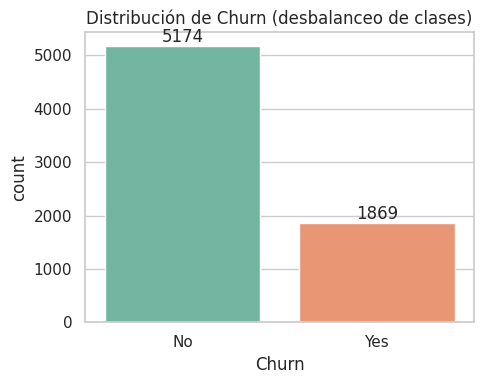

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
order = df_raw["Churn"].value_counts().index
sns.countplot(data=df_raw, x="Churn", order=order, ax=ax, palette="Set2")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribución de Churn (desbalanceo de clases)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig01_churn_balance.png"), dpi=150)
plt.show()


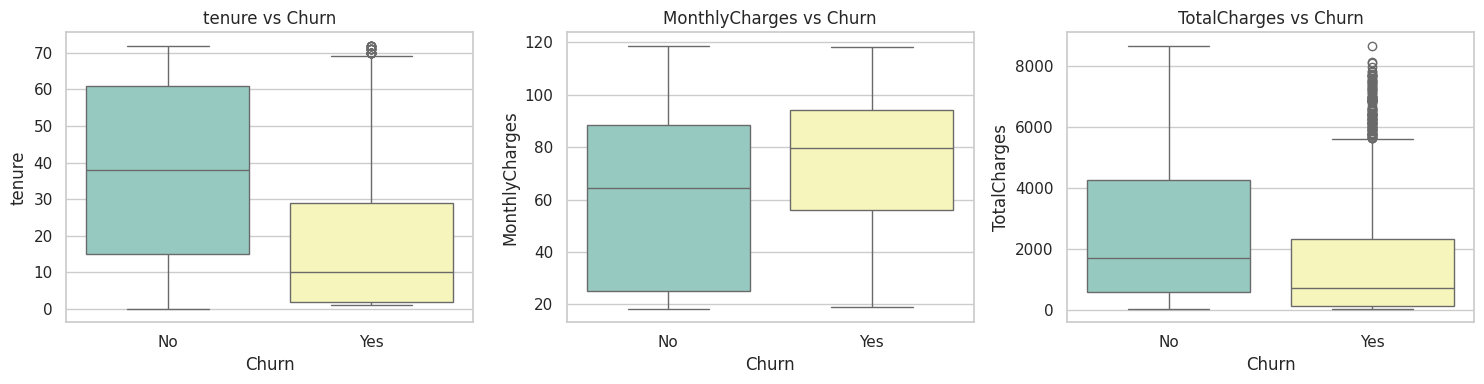

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df_raw, x="Churn", y=col, ax=ax, palette="Set3")
    ax.set_title(f"{col} vs Churn")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig02_numeric_vs_churn.png"), dpi=150)
plt.show()


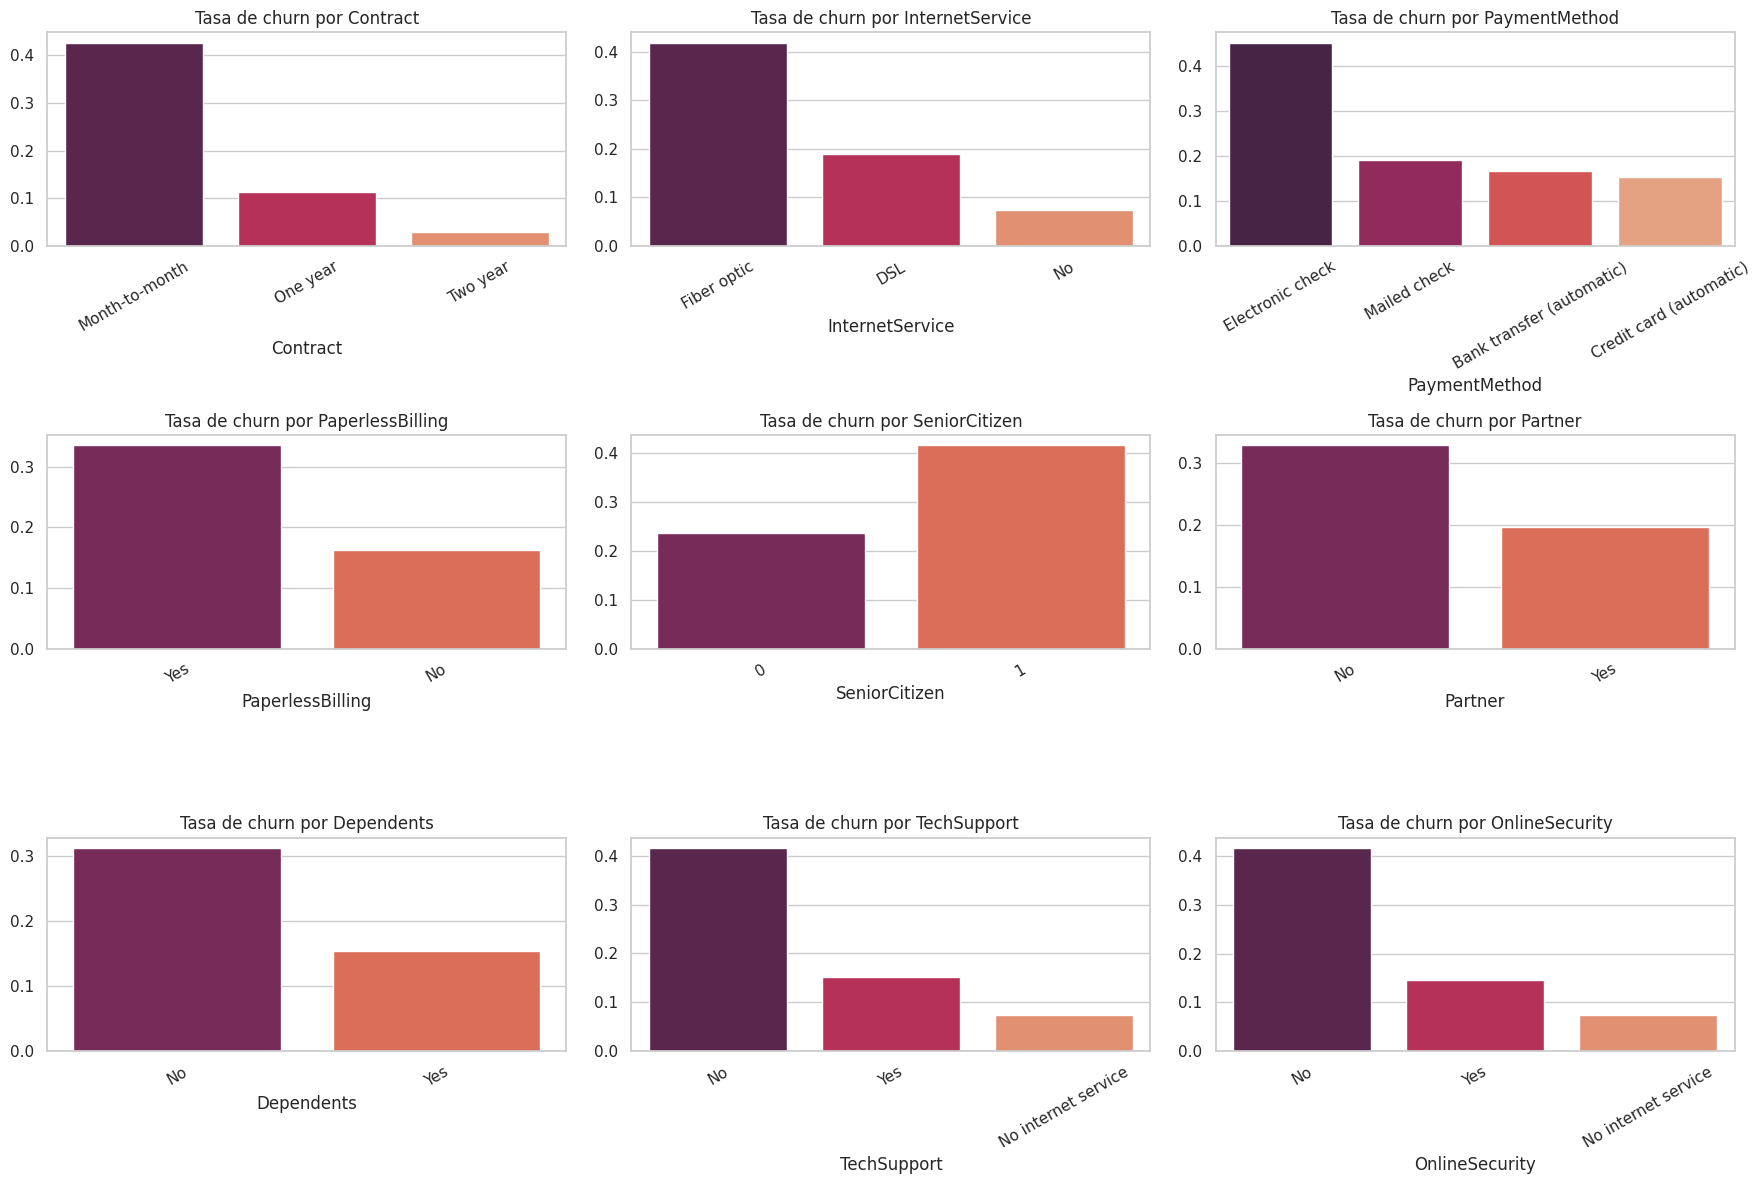

In [5]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
            "SeniorCitizen", "Partner", "Dependents", "TechSupport", "OnlineSecurity"]
df_plot = df_raw.copy()
df_plot["ChurnFlag"] = (df_plot["Churn"] == "Yes").astype(int)

ncols = 3
nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)
for i, col in enumerate(cat_cols):
    rate = df_plot.groupby(col)["ChurnFlag"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=axes[i], palette="rocket")
    axes[i].set_title(f"Tasa de churn por {col}")
    axes[i].tick_params(axis="x", rotation=30)
for j in range(i + 1, len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig03_churn_rate_categoricas.png"), dpi=150)
plt.show()


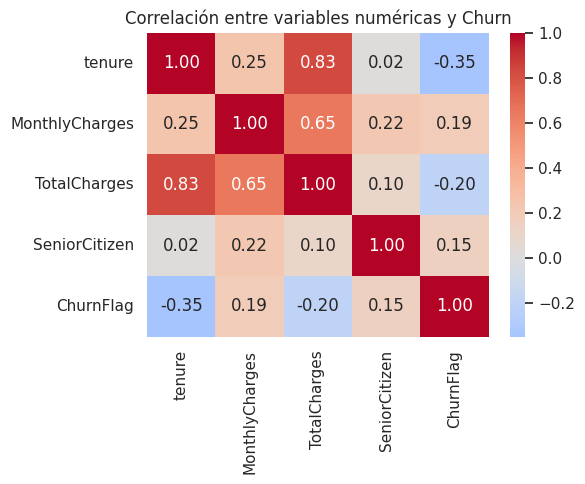

In [6]:
df_num = df_raw.copy()
df_num["ChurnFlag"] = (df_num["Churn"] == "Yes").astype(int)
df_num["SeniorCitizen"] = df_num["SeniorCitizen"].astype(int)
corr = df_num[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación entre variables numéricas y Churn")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig04_correlacion.png"), dpi=150)
plt.show()


## 2. Preprocesado y Feature Engineering

- `TotalCharges` vacío (tenure=0) → se imputa a 0.
- Categorías "No internet/phone service" → colapsadas a "No" (evita multicolinealidad).
- Nuevas variables: `AvgMonthlySpend`, `NumServices`, `TenureGroup`, `HighRiskContract`.
- Codificación: Label Encoding (binarias) + One-Hot (Contract, InternetService, PaymentMethod, TenureGroup).


In [7]:
from sklearn.preprocessing import LabelEncoder

def clean(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
    for col in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]:
        df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})
    return df

def feature_engineering(df):
    df = df.copy()
    df["AvgMonthlySpend"] = df["TotalCharges"] / df["tenure"].replace(0, 1)
    yes_services = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                     "TechSupport", "StreamingTV", "StreamingMovies"]
    df["NumServices"] = (df[yes_services] == "Yes").sum(axis=1) + (df["InternetService"] != "No").astype(int) \
        + (df["PhoneService"] == "Yes").astype(int)
    bins = [0, 12, 24, 48, 73]
    labels = ["0-12m", "12-24m", "24-48m", "48-72m"]
    df["TenureGroup"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)
    df["HighRiskContract"] = (df["Contract"] == "Month-to-month").astype(int)
    return df

def encode(df):
    df = df.copy()
    df["Churn"] = (df["Churn"] == "Yes").astype(int)
    binary_cols = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                   "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                   "StreamingTV", "StreamingMovies", "PaperlessBilling"]
    le = LabelEncoder()
    for col in binary_cols:
        df[col] = le.fit_transform(df[col])
    df = pd.get_dummies(df, columns=["InternetService", "Contract", "PaymentMethod", "TenureGroup"], drop_first=True)
    return df

df_proc = encode(feature_engineering(clean(df_raw)))
df_proc.to_csv(os.path.join("../data/processed", "telco_processed.csv"), index=False)
print(df_proc.shape)
df_proc.head()


(7043, 31)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,...,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_12-24m,TenureGroup_24-48m,TenureGroup_48-72m
0,7590-VHVEG,0,0,1,0,1,0,0,0,1,...,False,False,False,False,False,True,False,False,False,False
1,5575-GNVDE,1,0,0,0,34,1,0,1,0,...,False,False,True,False,False,False,True,False,True,False
2,3668-QPYBK,1,0,0,0,2,1,0,1,1,...,False,False,False,False,False,False,True,False,False,False
3,7795-CFOCW,1,0,0,0,45,0,0,1,0,...,False,False,True,False,False,False,False,False,True,False
4,9237-HQITU,0,0,0,0,2,1,0,0,0,...,True,False,False,False,False,True,False,False,False,False


## 3. Modelos de clasificación: Regresión Logística, XGBoost, MLP

Objetivo específico 2 del anteproyecto. Incluye selección de variables (SelectKBest),
balanceo de clases (SMOTE) **dentro de cada fold de CV** (evita fuga de información),
y ajuste de hiperparámetros con `GridSearchCV`/`RandomizedSearchCV` sobre 5-fold CV
estratificado, optimizando AUC-ROC. La evaluación final se hace sobre un hold-out test
que el tuning nunca ve.

Nota metodológica: `StandardScaler` y `SelectKBest` se ajustan **una sola vez** sobre `X_train`, fuera de los folds de CV
(solo SMOTE y el clasificador están dentro del `Pipeline`). Por eso las métricas de CV pueden ser algo optimistas;
las de test no se ven afectadas.


In [8]:
import joblib
import json
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

y = df_proc["Churn"].values
X = df_proc.drop(columns=["Churn", "customerID"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

K_FEATURES = 15
selector = SelectKBest(score_func=f_classif, k=min(K_FEATURES, X_train.shape[1]))
X_train_sel = selector.fit_transform(X_train_scaled, y_train)
X_test_sel = selector.transform(X_test_scaled)
selected_cols = X_train.columns[selector.get_support()]
scores = pd.Series(selector.scores_, index=X_train.columns).sort_values(ascending=False)
print("Top variables (SelectKBest):")
print(scores.head(K_FEATURES))


Top variables (SelectKBest):
HighRiskContract                  1033.347196
tenure                             704.893822
InternetService_Fiber optic        563.175942
PaymentMethod_Electronic check     533.708016
Contract_Two year                  521.083285
TenureGroup_48-72m                 361.401236
InternetService_No                 293.474433
PaperlessBilling                   225.046563
MonthlyCharges                     213.976502
AvgMonthlySpend                    213.605102
TotalCharges                       201.806435
Contract_One year                  176.716213
OnlineSecurity                     164.767056
TechSupport                        151.458954
Dependents                         150.560599
dtype: float64


In [9]:
CV_FOLDS = 5
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

base_models = {
    "Regresion_Logistica": LogisticRegression(max_iter=2000, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
    "MLP": MLPClassifier(max_iter=500, random_state=42, early_stopping=True),
}

param_grids = {
    "Regresion_Logistica": {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__penalty": ["l2"], "clf__solver": ["lbfgs"]},
    "XGBoost": {
        "clf__n_estimators": [100, 200, 300], "clf__max_depth": [3, 4, 5],
        "clf__learning_rate": [0.03, 0.05, 0.1], "clf__subsample": [0.8, 1.0], "clf__colsample_bytree": [0.8, 1.0],
    },
    "MLP": {
        "clf__hidden_layer_sizes": [(32,), (32, 16)], "clf__alpha": [0.0001, 0.001, 0.01],
        "clf__learning_rate_init": [0.001, 0.01],
    },
}

# n_jobs=1 deliberado: evita crashes silenciosos del backend de multiproceso de joblib
# en algunos entornos en contenedor. Es mas lento pero fiable.
all_metrics, cv_summary_rows = [], []
fitted_models, models_pred, models_prob = {}, {}, {}

for name, base_model in base_models.items():
    print(f">>> Tuning {name}...")
    pipe = ImbPipeline([("smote", SMOTE(random_state=42)), ("clf", base_model)])
    if name == "Regresion_Logistica":
        search = GridSearchCV(pipe, param_grids[name], scoring="roc_auc", cv=cv, n_jobs=1)
    else:
        search = RandomizedSearchCV(pipe, param_grids[name], n_iter=12, scoring="roc_auc",
                                     cv=cv, random_state=42, n_jobs=1)
    search.fit(X_train_sel, y_train)
    best_model = search.best_estimator_
    fitted_models[name] = best_model
    cv_summary_rows.append({"modelo": name, "mejor_auc_cv_mean": round(search.best_score_, 4),
                             "mejores_hiperparametros": json.dumps(search.best_params_, ensure_ascii=False)})
    print(f"  Mejor AUC-ROC (CV {CV_FOLDS}-fold): {search.best_score_:.4f} | params: {search.best_params_}")

    y_prob = best_model.predict_proba(X_test_sel)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    metrics = {
        "modelo": name,
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "f1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "auc_roc": round(roc_auc_score(y_test, y_prob), 4),
    }
    all_metrics.append(metrics)
    models_pred[name], models_prob[name] = y_pred, y_prob
    joblib.dump(best_model, os.path.join(MODELS_DIR, f"{name}.joblib"))
    print(f"  Metricas hold-out test: {metrics}")

results_df = pd.DataFrame(all_metrics)
results_df.to_csv(os.path.join(REPORTS_DIR, "model_comparison.csv"), index=False)
pd.DataFrame(cv_summary_rows).to_csv(os.path.join(REPORTS_DIR, "cv_hyperparameter_tuning.csv"), index=False)
joblib.dump(scaler, os.path.join(MODELS_DIR, "scaler.joblib"))
with open(os.path.join(MODELS_DIR, "selected_features.json"), "w") as f:
    json.dump(list(selected_cols), f, indent=2, ensure_ascii=False)
results_df


>>> Tuning Regresion_Logistica...


  Mejor AUC-ROC (CV 5-fold): 0.8414 | params: {'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}
  Metricas hold-out test: {'modelo': 'Regresion_Logistica', 'accuracy': 0.7456, 'precision': np.float64(0.5132), 'recall': np.float64(0.7923), 'f1': np.float64(0.6229), 'auc_roc': np.float64(0.8413)}
>>> Tuning XGBoost...


  Mejor AUC-ROC (CV 5-fold): 0.8438 | params: {'clf__subsample': 0.8, 'clf__n_estimators': 300, 'clf__max_depth': 3, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.8}
  Metricas hold-out test: {'modelo': 'XGBoost', 'accuracy': 0.7615, 'precision': np.float64(0.5339), 'recall': np.float64(0.7923), 'f1': np.float64(0.6379), 'auc_roc': np.float64(0.8415)}
>>> Tuning MLP...


  Mejor AUC-ROC (CV 5-fold): 0.8367 | params: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (32,), 'clf__alpha': 0.0001}
  Metricas hold-out test: {'modelo': 'MLP', 'accuracy': 0.7462, 'precision': np.float64(0.514), 'recall': np.float64(0.7837), 'f1': np.float64(0.6209), 'auc_roc': np.float64(0.8436)}


,modelo,accuracy,precision,recall,f1,auc_roc
0,Regresion_Logistica,0.7456,0.5132,0.7923,0.6229,0.8413
1,XGBoost,0.7615,0.5339,0.7923,0.6379,0.8415
2,MLP,0.7462,0.5140,0.7837,0.6209,0.8436


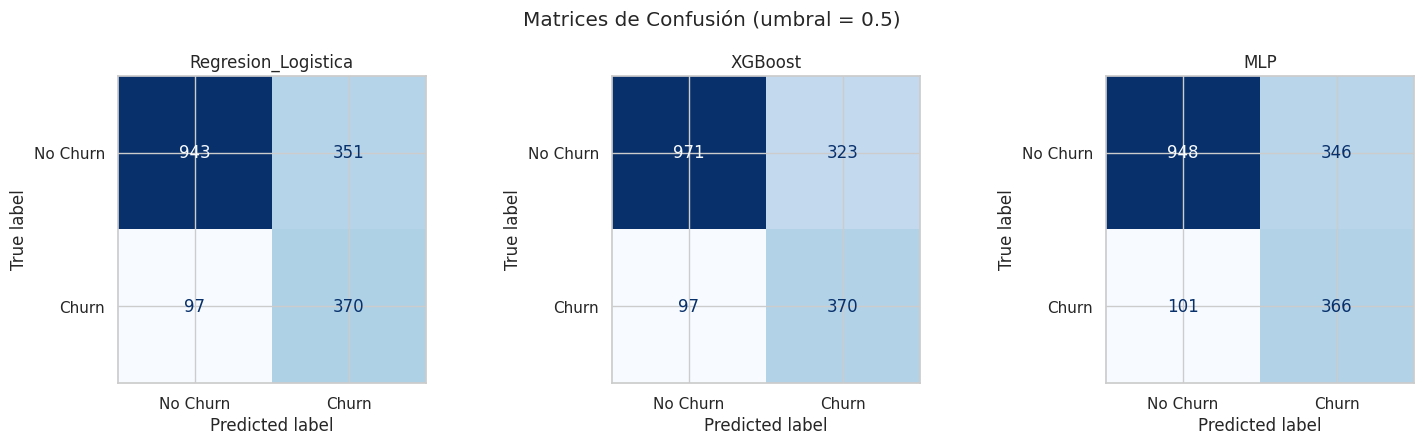

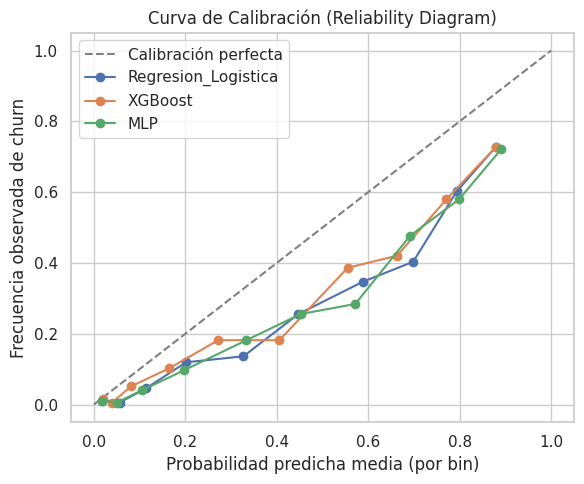

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, y_pred) in zip(axes, models_pred.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
fig.suptitle("Matrices de Confusión (umbral = 0.5)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig12_matrices_confusion.png"), dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibración perfecta")
for name, y_prob in models_prob.items():
    frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.set_xlabel("Probabilidad predicha media (por bin)"); ax.set_ylabel("Frecuencia observada de churn")
ax.set_title("Curva de Calibración (Reliability Diagram)"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig13_calibracion.png"), dpi=150)
plt.show()


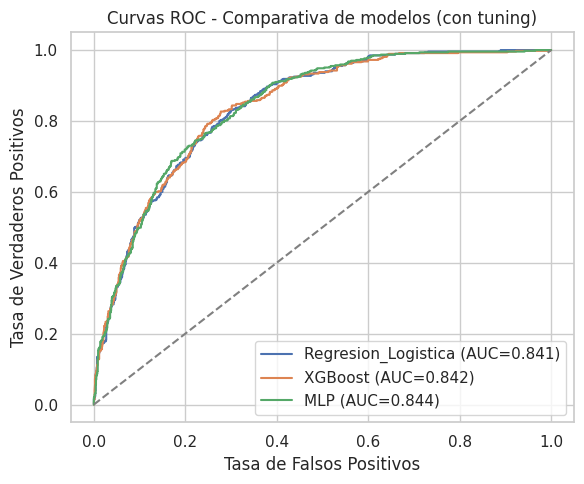

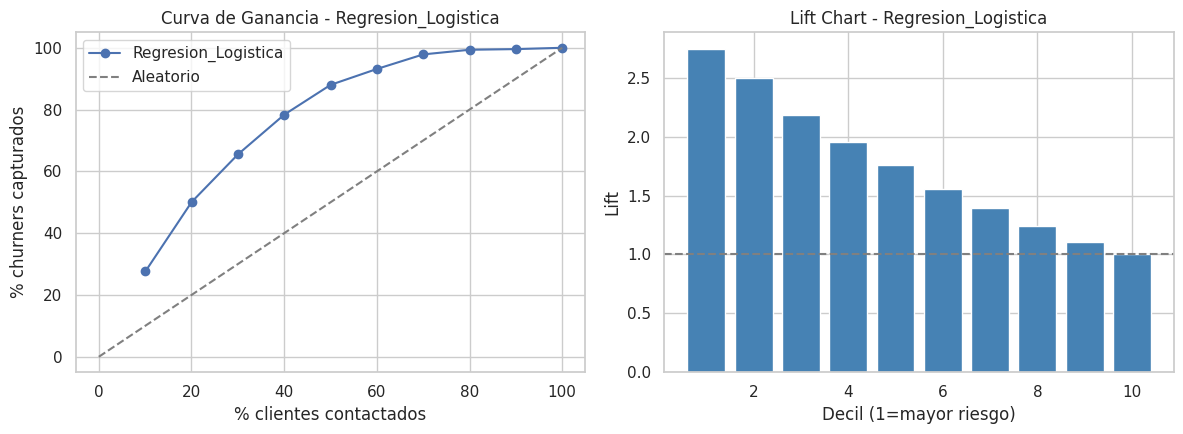

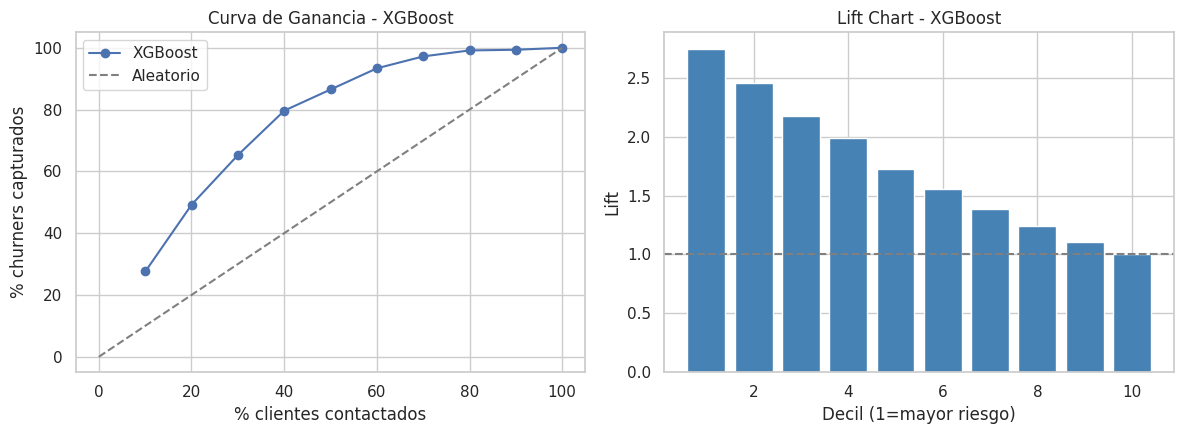

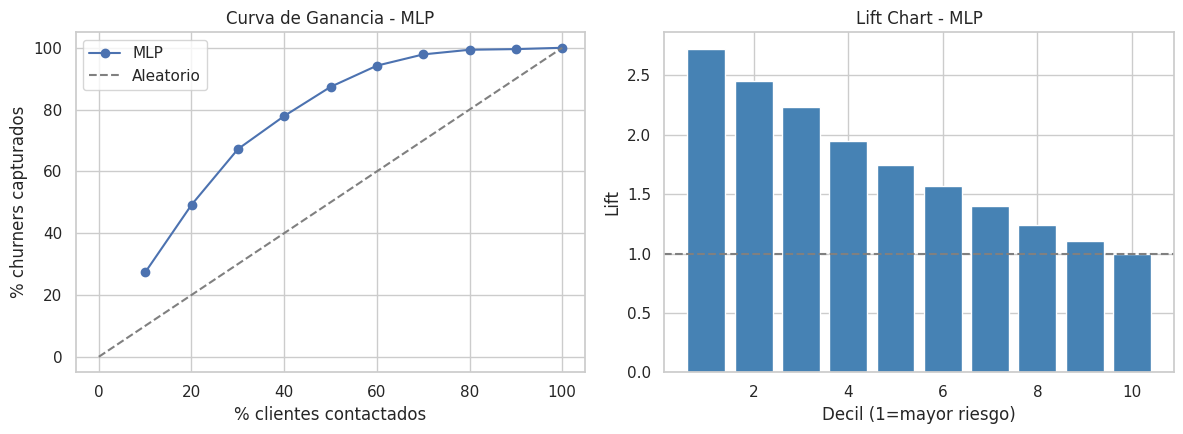

In [11]:
# Curva ROC comparativa + curva de ganancia / lift para XGBoost
fig, ax = plt.subplots(figsize=(6, 5))
for name, y_prob in models_prob.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_prob):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("Tasa de Falsos Positivos"); ax.set_ylabel("Tasa de Verdaderos Positivos")
ax.set_title("Curvas ROC - Comparativa de modelos (con tuning)"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig05_roc_comparativa.png"), dpi=150)
plt.show()

def gain_lift_chart(y_true, y_prob, model_name):
    d = pd.DataFrame({"y": y_true, "p": y_prob}).sort_values("p", ascending=False).reset_index(drop=True)
    d["decile"] = pd.qcut(d.index, 10, labels=False, duplicates="drop")
    total_pos = d["y"].sum(); n = len(d)
    gain = d.groupby("decile")["y"].sum().cumsum() / total_pos * 100
    pct_customers = d.groupby("decile").size().cumsum() / n * 100
    lift = gain / pct_customers
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(pct_customers, gain, marker="o", label=model_name)
    axes[0].plot([0, 100], [0, 100], linestyle="--", color="gray", label="Aleatorio")
    axes[0].set_xlabel("% clientes contactados"); axes[0].set_ylabel("% churners capturados")
    axes[0].set_title(f"Curva de Ganancia - {model_name}"); axes[0].legend()
    axes[1].bar(range(1, len(lift) + 1), lift.values, color="steelblue")
    axes[1].axhline(1, linestyle="--", color="gray")
    axes[1].set_xlabel("Decil (1=mayor riesgo)"); axes[1].set_ylabel("Lift")
    axes[1].set_title(f"Lift Chart - {model_name}")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"fig_gain_lift_{model_name}.png"), dpi=150)
    plt.show()

for name, y_prob in models_prob.items():
    gain_lift_chart(y_test, y_prob, name)


## 4. Modelo de supervivencia (Cox PH) + CLV dinámico

Este es el bloque que justifica el título del TFM. `duration = tenure`, `event = Churn`
(1 = abandono observado, 0 = censurado / sigue activo). Es la forma estándar de tratar
este dataset como snapshot de supervivencia. Limitación: no hay fecha de alta real ni seguimiento longitudinal.


                      coef  exp(coef)              p
covariate                                           
Fiber             0.532650   1.703441   1.229880e-25
Paperless         0.234915   1.264801   1.355486e-07
SeniorCitizen     0.088699   1.092751   6.735214e-02
MonthlyCharges   -0.004125   0.995883   2.089874e-06
Contract_OneYear -1.106288   0.330785   2.572736e-94
Contract_TwoYear -1.660538   0.190037  2.628032e-184


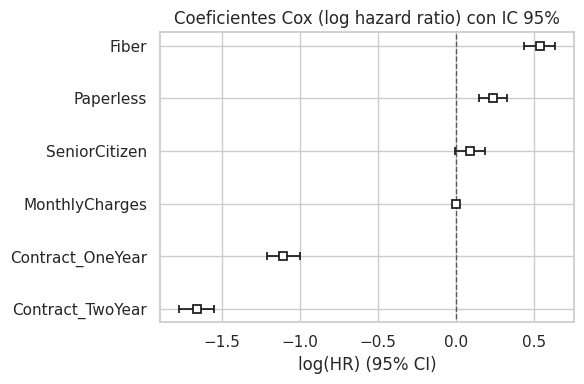

In [12]:
from lifelines import CoxPHFitter, KaplanMeierFitter

df_surv = df_raw.copy()
df_surv["TotalCharges"] = pd.to_numeric(df_surv["TotalCharges"], errors="coerce").fillna(0.0)
df_surv["event"] = (df_surv["Churn"] == "Yes").astype(int)
df_surv["duration"] = df_surv["tenure"].clip(lower=1)

df_cox = df_surv[["duration", "event", "MonthlyCharges", "SeniorCitizen"]].copy()
df_cox["Contract_OneYear"] = (df_surv["Contract"] == "One year").astype(int)
df_cox["Contract_TwoYear"] = (df_surv["Contract"] == "Two year").astype(int)
df_cox["Fiber"] = (df_surv["InternetService"] == "Fiber optic").astype(int)
df_cox["Paperless"] = (df_surv["PaperlessBilling"] == "Yes").astype(int)

cph = CoxPHFitter(penalizer=0.1)
cph.fit(df_cox, duration_col="duration", event_col="event")
summary = cph.summary[["coef", "exp(coef)", "p"]].sort_values("exp(coef)", ascending=False)
summary.to_csv(os.path.join(REPORTS_DIR, "cox_hazard_ratios.csv"))
print(summary)

fig, ax = plt.subplots(figsize=(6, 4))
cph.plot(ax=ax)
ax.set_title("Coeficientes Cox (log hazard ratio) con IC 95%")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig06_cox_coeficientes.png"), dpi=150)
plt.show()


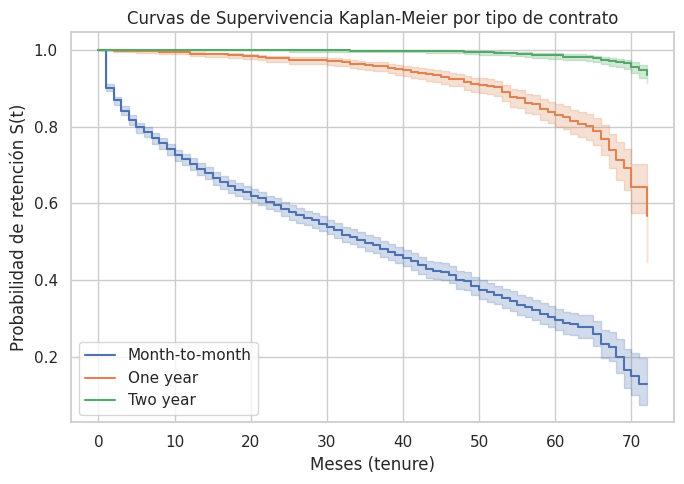

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
kmf = KaplanMeierFitter()
for contract_type in df_surv["Contract"].unique():
    mask = df_surv["Contract"] == contract_type
    kmf.fit(df_surv.loc[mask, "duration"], df_surv.loc[mask, "event"], label=contract_type)
    kmf.plot_survival_function(ax=ax)
ax.set_title("Curvas de Supervivencia Kaplan-Meier por tipo de contrato")
ax.set_xlabel("Meses (tenure)"); ax.set_ylabel("Probabilidad de retención S(t)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig07_kaplan_meier_contrato.png"), dpi=150)
plt.show()


In [14]:
HORIZON = 24  # meses de horizonte de negocio para el CLV
surv_funcs = cph.predict_survival_function(df_cox, times=np.arange(1, HORIZON + 1))
rmst = surv_funcs.sum(axis=0)

clv_df = pd.DataFrame({
    "customerID": df_surv["customerID"].values,
    "MonthlyCharges": df_surv["MonthlyCharges"].values,
    "tenure_actual": df_surv["tenure"].values,
    "Churn_actual": df_surv["Churn"].values,
    f"RMST_{HORIZON}m": rmst.values,
})
clv_df[f"CLV_{HORIZON}m"] = clv_df["MonthlyCharges"] * clv_df[f"RMST_{HORIZON}m"]
clv_df = clv_df.sort_values(f"CLV_{HORIZON}m", ascending=False)
clv_df.to_csv(os.path.join(REPORTS_DIR, "clv_estimado.csv"), index=False)

print(f"CLV medio de la cartera: {clv_df[f'CLV_{HORIZON}m'].mean():.2f} EUR")
print(f"CLV total de la cartera: {clv_df[f'CLV_{HORIZON}m'].sum():.2f} EUR")
clv_df.head(10)


CLV medio de la cartera: 1294.92 EUR
CLV total de la cartera: 9120111.49 EUR


,customerID,MonthlyCharges,tenure_actual,Churn_actual,RMST_24m,CLV_24m
3894,5989-AXPUC,118.60,68,No,22.976412,2725.002516
6768,9739-JLPQJ,117.50,72,No,22.971870,2699.194743
4586,7569-NMZYQ,118.75,72,No,22.714372,2697.331672
2115,8984-HPEMB,118.65,71,No,22.713858,2694.999214
6118,9924-JPRMC,118.20,72,No,22.711541,2684.504133
3205,3810-DVDQQ,117.60,72,No,22.708446,2670.513197
6289,9053-JZFKV,116.20,67,Yes,22.966477,2668.704588
4600,1741-WTPON,115.85,56,No,22.965020,2660.497551
2368,6650-BWFRT,117.15,72,No,22.706119,2660.021879
4620,8513-OLYGY,115.80,72,No,22.964812,2659.325181


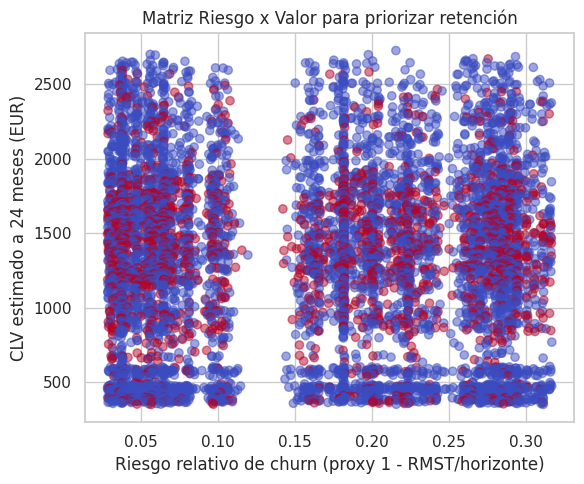

In [15]:
risk_proxy = 1 - rmst.values / HORIZON
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(risk_proxy, clv_df[f"CLV_{HORIZON}m"], c=(clv_df["Churn_actual"] == "Yes"), cmap="coolwarm", alpha=0.5)
ax.set_xlabel("Riesgo relativo de churn (proxy 1 - RMST/horizonte)")
ax.set_ylabel(f"CLV estimado a {HORIZON} meses (EUR)")
ax.set_title("Matriz Riesgo x Valor para priorizar retención")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig08_matriz_riesgo_valor.png"), dpi=150)
plt.show()


## 5. Explicabilidad (SHAP)

Objetivo específico 6 del anteproyecto: explicabilidad global y local con SHAP sobre el modelo XGBoost.

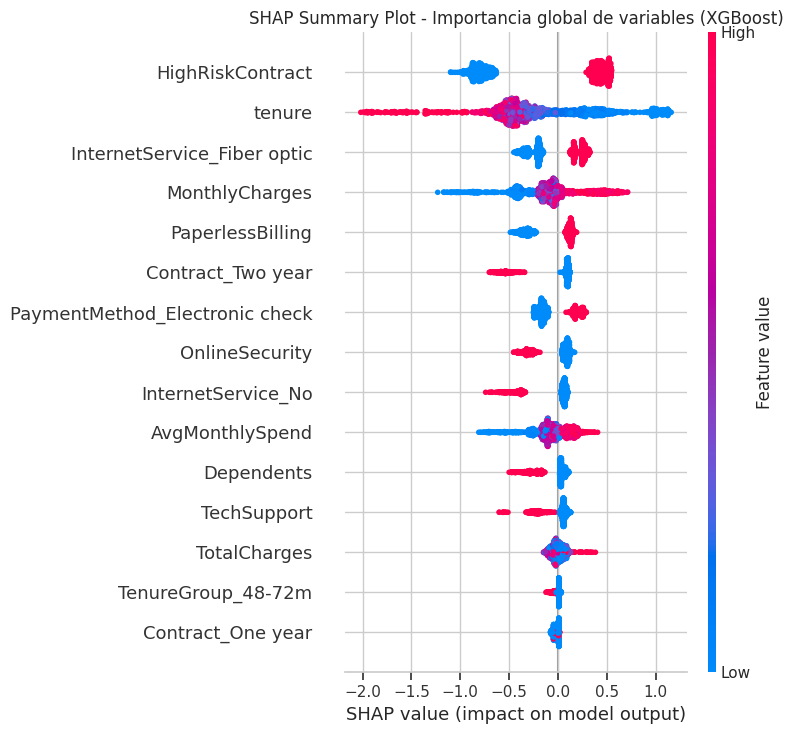

,feature,mean_abs_shap
8,HighRiskContract,0.601308
1,tenure,0.516457
9,InternetService_Fiber optic,0.248650
5,MonthlyCharges,0.236880
4,PaperlessBilling,0.208237
12,Contract_Two year,0.204430
13,PaymentMethod_Electronic check,0.183853
2,OnlineSecurity,0.149628
10,InternetService_No,0.145074
7,AvgMonthlySpend,0.139896


In [16]:
import shap

X_sel_full = X.copy()
X_scaled_full = pd.DataFrame(scaler.transform(X_sel_full), columns=X_sel_full.columns)[selected_cols]
X_train_shap, X_test_shap, y_train_shap, y_test_shap = train_test_split(
    X_scaled_full, y, test_size=0.25, random_state=42, stratify=y
)

# fitted_models["XGBoost"] es un imblearn.Pipeline (SMOTE + XGBClassifier); SHAP
# TreeExplainer necesita el estimador de arbol puro, no el pipeline completo.
xgb_model = fitted_models["XGBoost"].named_steps["clf"]
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_shap)

shap.summary_plot(shap_values, X_test_shap, show=False)
plt.title("SHAP Summary Plot - Importancia global de variables (XGBoost)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig09_shap_summary.png"), dpi=150, bbox_inches="tight")
plt.show()

mean_abs_shap = pd.DataFrame({
    "feature": X_test_shap.columns,
    "mean_abs_shap": abs(shap_values.values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)
mean_abs_shap.to_csv(os.path.join(REPORTS_DIR, "shap_importancia_global.csv"), index=False)
mean_abs_shap.head(10)


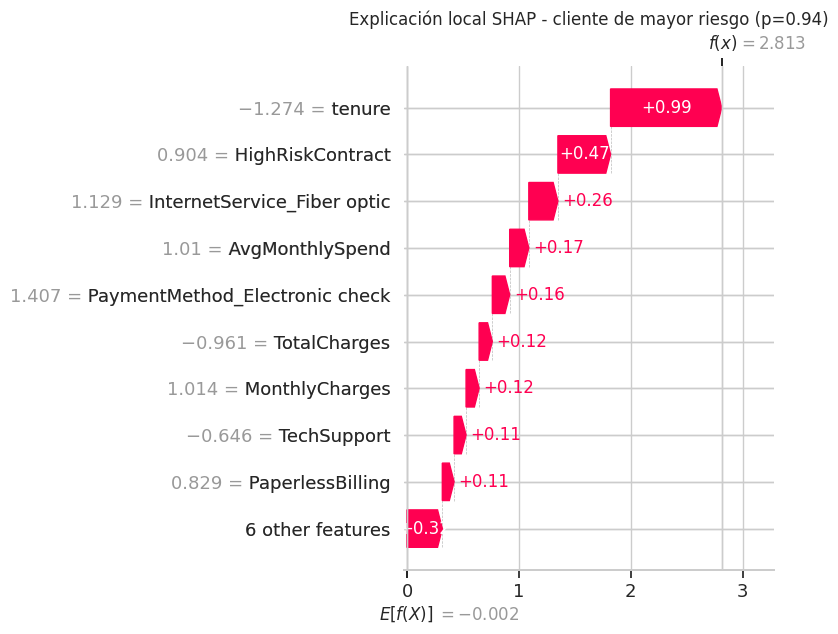

In [17]:
probs = fitted_models["XGBoost"].predict_proba(X_test_shap)[:, 1]
idx_riesgo = probs.argmax()
shap.plots.waterfall(shap_values[idx_riesgo], show=False)
plt.title(f"Explicación local SHAP - cliente de mayor riesgo (p={probs[idx_riesgo]:.2f})")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig10_shap_waterfall_cliente_riesgo.png"), dpi=150, bbox_inches="tight")
plt.show()


## 6. Supervivencia ampliada: Cox completo, riesgos proporcionales y DeepSurv

Objetivo de la ampliación: comparar sobre la **misma partición train/test** tres modelos de supervivencia
(Cox pequeño de 6 covariables, Cox completo de 21 covariables y DeepSurv), contrastar el supuesto de riesgos proporcionales (test de Schoenfeld),
ajustar un Cox estratificado por contrato, evaluar la calibración de S(24 meses) y recalcular el CLV con cada modelo.

DeepSurv (Katzman et al., 2018) está implementado en NumPy en `src/deepsurv_numpy.py`: un perceptrón multicapa que predice el log-riesgo η(x)
y se entrena minimizando la verosimilitud parcial de Cox (Breslow) con penalización L2. La función `_self_check()` verifica el gradiente
analítico frente a diferencias finitas.


In [18]:
import sys, inspect, importlib
sys.path.append("../src")
import deepsurv_numpy
deepsurv_numpy._self_check()          # gradiente analítico vs diferencias finitas + aprende señal
print(inspect.getsource(deepsurv_numpy.DeepSurv))


self-check DeepSurv OK
class DeepSurv:
    def __init__(self, hidden=(32, 16), l2=1e-3, lr=5e-3, epochs=300, seed=0, dropout=0.0):
        self.hidden, self.l2, self.lr, self.epochs = tuple(hidden), l2, lr, epochs
        self.seed, self.dropout = seed, dropout
        self.loss_history = []

    # ---------- verosimilitud parcial de Cox (Breslow) ----------
    @staticmethod
    def _tie_groups(t_sorted):
        _, first, counts = np.unique(t_sorted, return_index=True, return_counts=True)
        first_idx = np.repeat(first, counts)
        last_idx = np.repeat(first + counts - 1, counts)
        return first_idx, last_idx

    def _cox_loss_grad(self, eta, d, first_idx, last_idx):
        m = eta.max()
        e = np.exp(eta - m)
        S = np.cumsum(e[::-1])[::-1][first_idx]          # suma de riesgo del conjunto en riesgo
        n_ev = max(d.sum(), 1.0)
        loss = -np.sum(d * (eta - m - np.log(S))) / n_ev
        A = np.cumsum(d / S)[last_idx]                   # sum_{i even

In [19]:
import matplotlib
sv = importlib.import_module("07_supervivencia_ampliada")
sv.main()   # Cox pequeño/completo/estratificado, test PH, CV de DeepSurv, calibración y CLV (≈ 30 s)
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)  # el script usa Agg: se restaura el backend del notebook


{'hidden': '(16,)', 'l2': 0.01, 'cindex_cv_mean': np.float64(0.865728133045532), 'cindex_cv_std': np.float64(0.006436473021751351)}


{'hidden': '(16,)', 'l2': 0.001, 'cindex_cv_mean': np.float64(0.8628452733555537), 'cindex_cv_std': np.float64(0.0064536061599229765)}


{'hidden': '(32, 16)', 'l2': 0.01, 'cindex_cv_mean': np.float64(0.856368042871263), 'cindex_cv_std': np.float64(0.008608304452517361)}


{'hidden': '(32, 16)', 'l2': 0.001, 'cindex_cv_mean': np.float64(0.8444397790542411), 'cindex_cv_std': np.float64(0.007502299091395519)}


{'hidden': '(64, 32)', 'l2': 0.01, 'cindex_cv_mean': np.float64(0.8429133607169138), 'cindex_cv_std': np.float64(0.008234799226110118)}


{'hidden': '(64, 32)', 'l2': 0.001, 'cindex_cv_mean': np.float64(0.8239135801523713), 'cindex_cv_std': np.float64(0.0064187979248625845)}


{
  "n_train": 5282,
  "n_test": 1761,
  "n_cov_full": 21,
  "cindex_test": {
    "Cox_pequeno": 0.7959963157690036,
    "Cox_completo": 0.8496766574619821,
    "DeepSurv": 0.8605826176425871
  },
  "ph_violaciones_cox_pequeno": 3,
  "ph_violaciones_cox_completo": 7,
  "cindex_cv": {
    "Cox_pequeno": [
      0.8023349671732675,
      0.011721395678905745
    ],
    "Cox_completo": [
      0.8596366951665125,
      0.009400009839590405
    ]
  },
  "deepsurv_mejor": {
    "hidden": [
      16
    ],
    "l2": 0.01,
    "cindex_cv": 0.865728133045532
  },
  "cindex_test_ic95": {
    "Cox_pequeno": [
      0.7797700944637909,
      0.8137596429620509
    ],
    "Cox_completo": [
      0.8349983514386505,
      0.8639593115858224
    ],
    "DeepSurv": [
      0.8478629839728443,
      0.8731106741324769
    ]
  },
  "diff_DeepSurv_menos_CoxCompleto_ic95": [
    0.005858560007613217,
    0.015827938180149596
  ],
  "calibracion_error_abs_medio_S24": {
    "Cox pequeño": 0.060250488279774

C-index en test: {'Cox_pequeno': 0.796, 'Cox_completo': 0.8497, 'DeepSurv': 0.8606}
IC 95% bootstrap: {'Cox_pequeno': [0.7798, 0.8138], 'Cox_completo': [0.835, 0.864], 'DeepSurv': [0.8479, 0.8731]}
Diferencia DeepSurv - Cox completo (IC 95%): [0.0059, 0.0158]
Error abs. medio de calibración S(24): {'Cox pequeño': 0.0603, 'Cox completo': 0.046, 'DeepSurv': 0.0172}
Violaciones de riesgos proporcionales: pequeño = 3 | completo = 7


,hidden,l2,cindex_cv_mean,cindex_cv_std
0,"(16,)",0.010,0.8657,0.0064
1,"(16,)",0.001,0.8628,0.0065
2,"(32, 16)",0.010,0.8564,0.0086
3,"(32, 16)",0.001,0.8444,0.0075
4,"(64, 32)",0.010,0.8429,0.0082
5,"(64, 32)",0.001,0.8239,0.0064


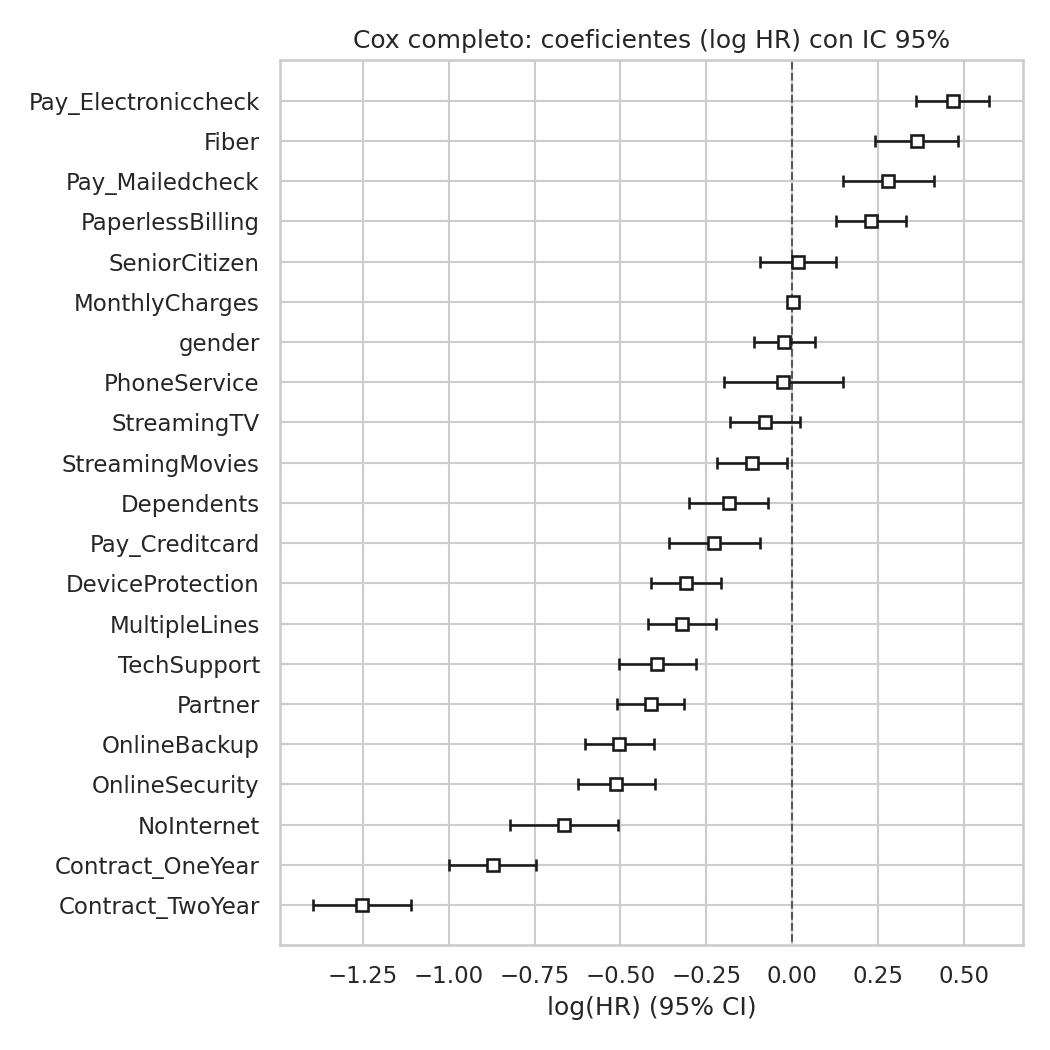

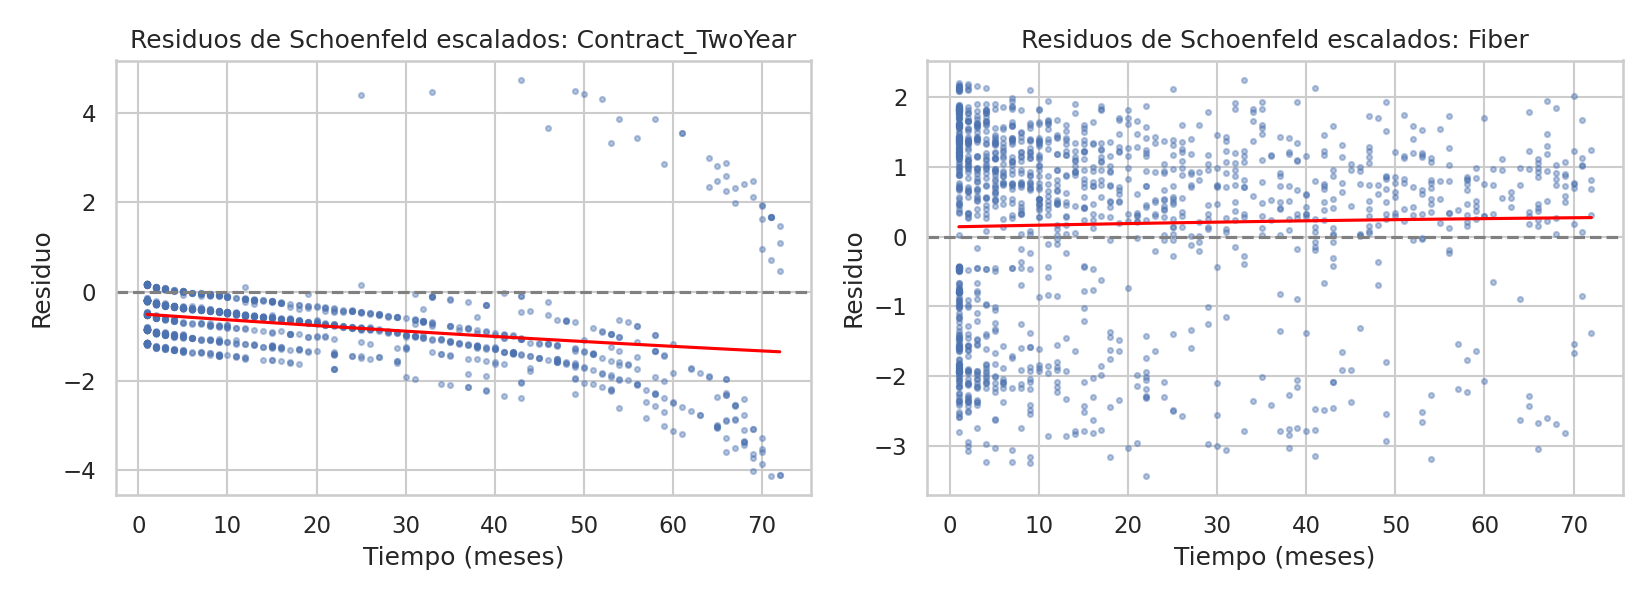

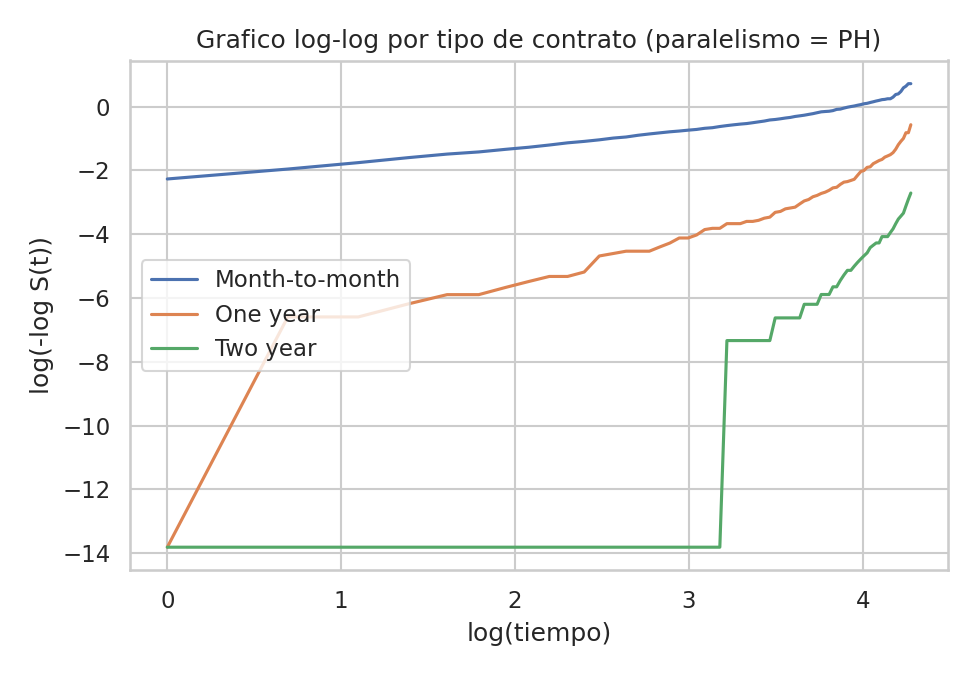

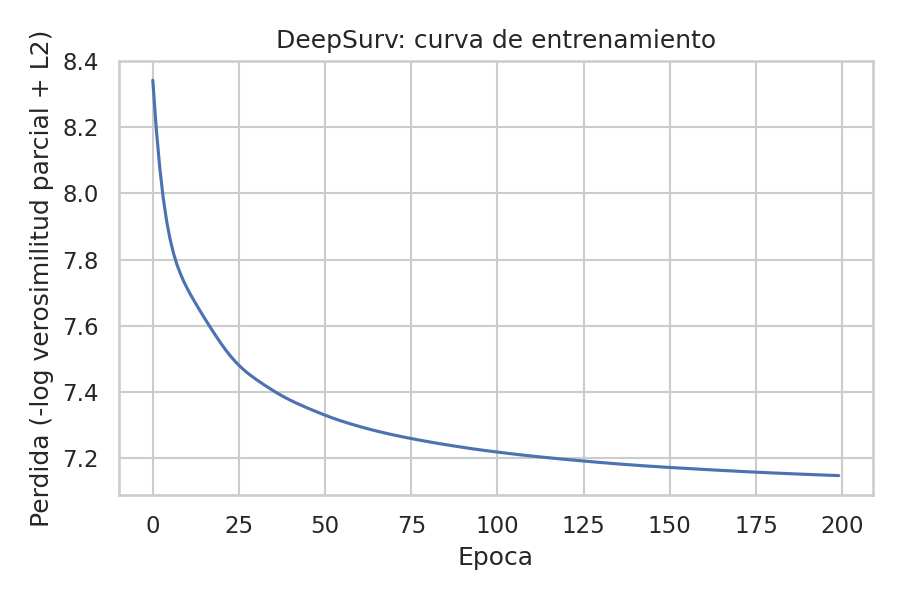

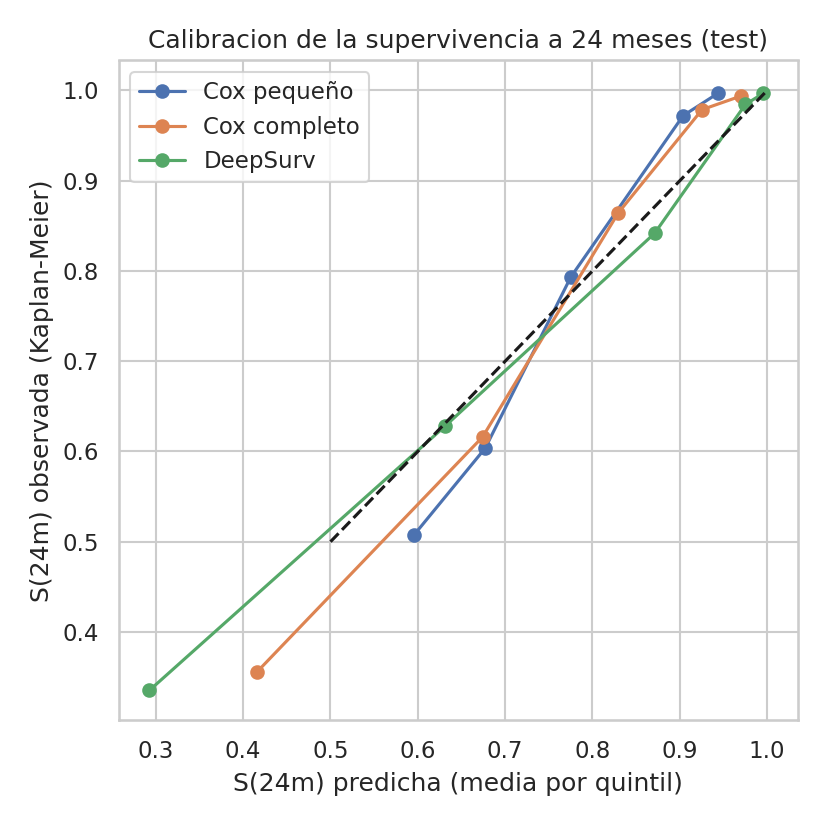

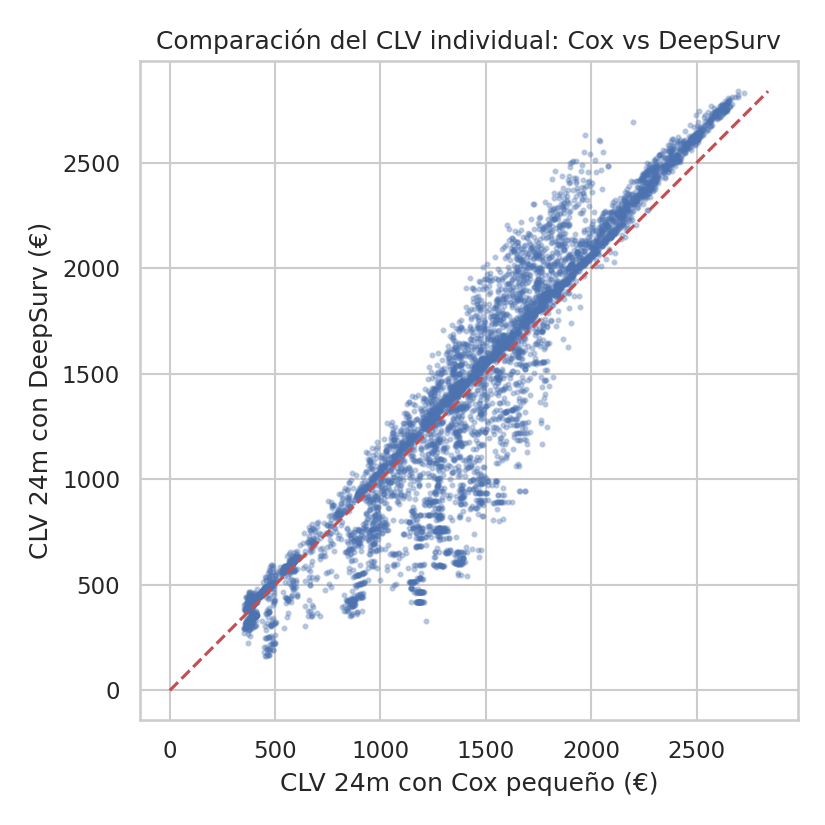

In [20]:
import json
from IPython.display import Image, display
res7 = json.load(open(os.path.join(REPORTS_DIR, "survival_ampliada_resultados.json")))
print("C-index en test:", {k: round(v, 4) for k, v in res7["cindex_test"].items()})
print("IC 95% bootstrap:", {k: [round(x, 4) for x in v] for k, v in res7["cindex_test_ic95"].items()})
print("Diferencia DeepSurv - Cox completo (IC 95%):", [round(x, 4) for x in res7["diff_DeepSurv_menos_CoxCompleto_ic95"]])
print("Error abs. medio de calibración S(24):", {k: round(v, 4) for k, v in res7["calibracion_error_abs_medio_S24"].items()})
print("Violaciones de riesgos proporcionales: pequeño =", res7["ph_violaciones_cox_pequeno"], "| completo =", res7["ph_violaciones_cox_completo"])
display(pd.read_csv(os.path.join(REPORTS_DIR, "survival_deepsurv_cv.csv")).round(4))
for f in ["fig20_cox_completo_forest", "fig21_schoenfeld", "fig22_km_loglog", "fig23_deepsurv_loss", "fig24_calibracion_supervivencia", "fig25_comparacion_clv"]:
    display(Image(os.path.join(FIG_DIR, f + ".png"), width=600))


## 7. Diagnósticos ampliados

EDA ampliado (antigüedad, servicios, contrato, pago), curvas de precisión-exhaustividad,
umbral de decisión óptimo según el coste de contacto (con las etiquetas reales del test), equidad por subgrupos (género, edad, pareja, personas a cargo y contrato)
y gráficos de dependencia SHAP.


In [21]:
dg = importlib.import_module("08_diagnosticos_ampliados")
dg.main()
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)


{
  "average_precision": {
    "Regresion_Logistica": 0.6369,
    "XGBoost": 0.6434,
    "MLP": 0.6414
  },
  "prevalencia_test": 0.26519023282226006,
  "umbral": {
    "coste_contacto": 15.0,
    "tasa_exito": 0.3,
    "umbral_max_beneficio": 0.08,
    "beneficio_max": 167825.44537603663,
    "clientes_contactados_umbral_opt": 1315,
    "beneficio_umbral_0.5": 138113.11014762893,
    "contactados_0.5": 693,
    "umbral_max_F1": 0.5,
    "beneficio_umbral_maxF1": 138113.11014762893,
    "beneficio_contactar_a_todos": 162558.59900435922,
    "n_test": 1761
  },
  "umbral_por_coste": [
    {
      "coste_contacto": 15,
      "umbral_optimo": 0.08,
      "beneficio_max": 167825.44537603663,
      "pct_contactados": 74.7,
      "beneficio_umbral_0_5": 138113.11014762893,
      "beneficio_contactar_a_todos": 162558.59900435922
    },
    {
      "coste_contacto": 50,
      "umbral_optimo": 0.26,
      "beneficio_max": 125819.85254780352,
      "pct_contactados": 56.2,
      "beneficio_umbra

Average precision (test): {'Regresion_Logistica': 0.6369, 'XGBoost': 0.6434, 'MLP': 0.6414} | prevalencia: 0.2652
Cambio de signo del efecto SHAP de tenure (meses): [12.0]


,variable,grupo,n,churn_real,AUC,tasa_contacto,recall,precision
0,gender,Female,863,0.278,0.834,0.400,0.779,0.542
1,gender,Male,898,0.253,0.848,0.388,0.806,0.526
2,Edad,Mayor (65+),286,0.427,0.791,0.650,0.918,0.602
3,Edad,No mayor,1475,0.234,0.844,0.344,0.748,0.509
4,Partner,No,892,0.336,0.821,0.527,0.860,0.549
5,Partner,Yes,869,0.192,0.847,0.257,0.671,0.502
6,Dependents,No,1220,0.311,0.827,0.491,0.847,0.538
7,Dependents,Yes,541,0.161,0.847,0.174,0.552,0.511
8,Contract,Month-to-month,968,0.428,0.741,0.690,0.874,0.542
9,Contract,One year,366,0.117,0.724,0.068,0.186,0.320


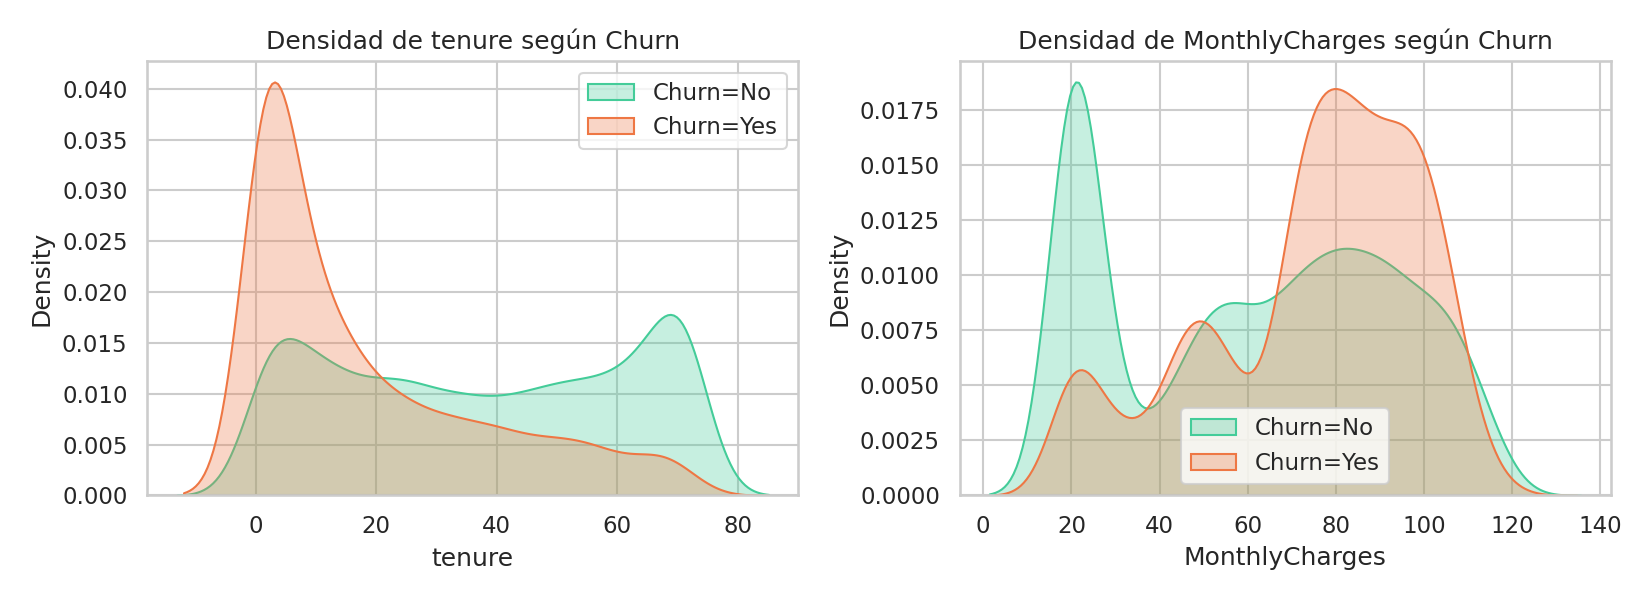

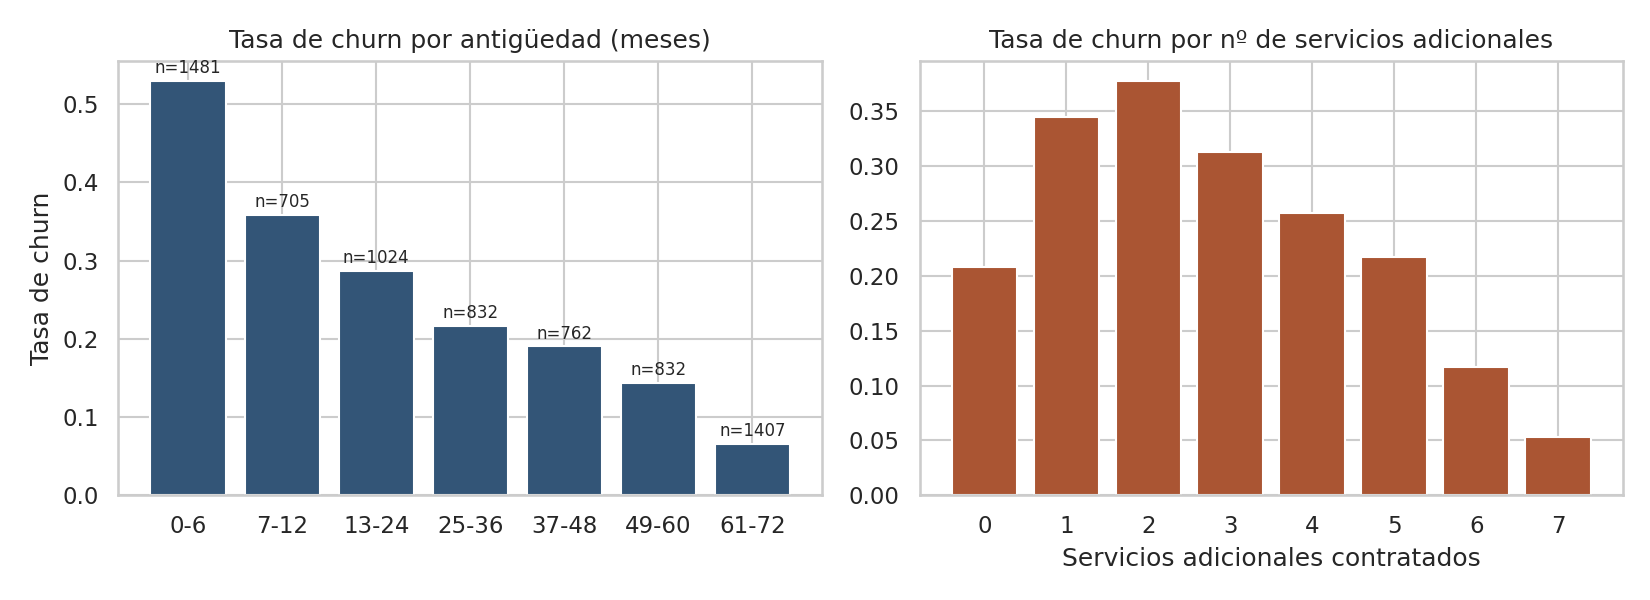

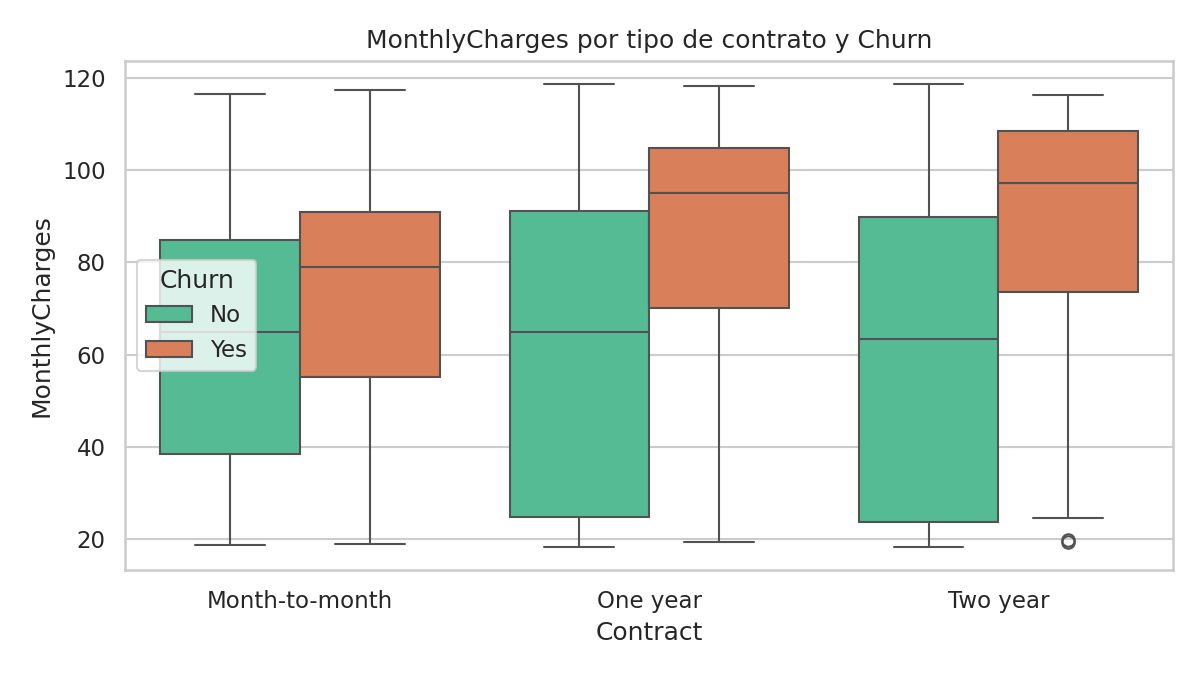

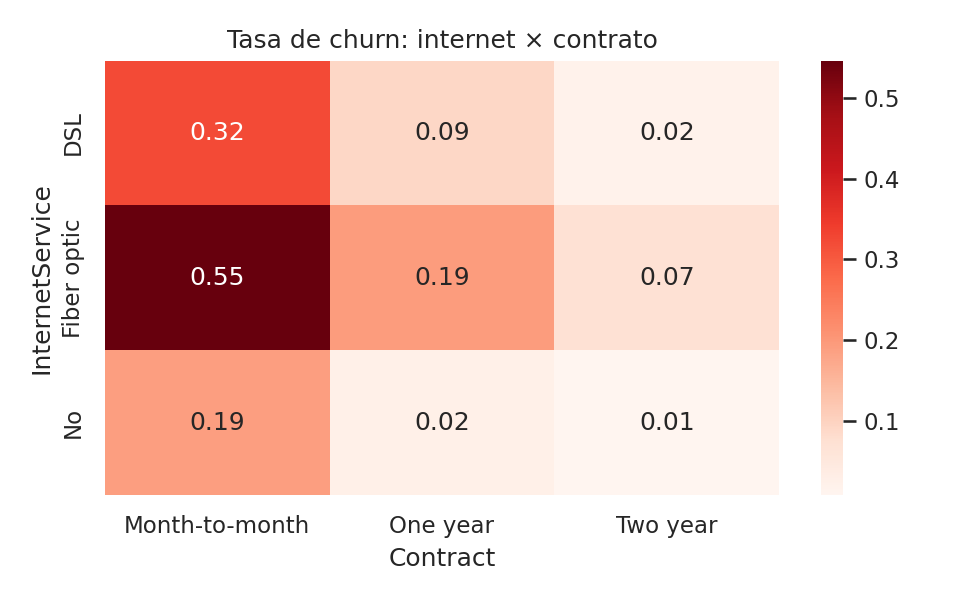

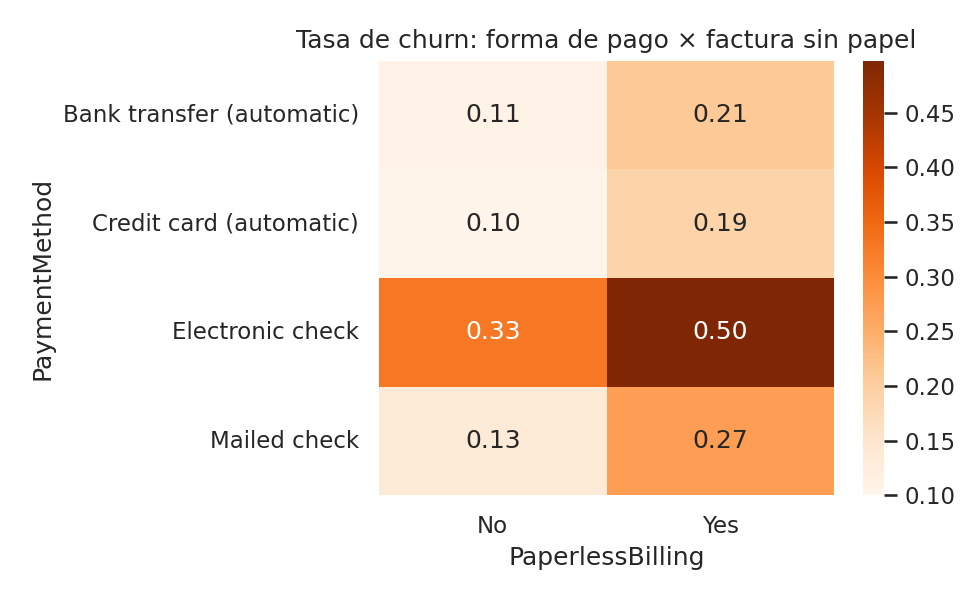

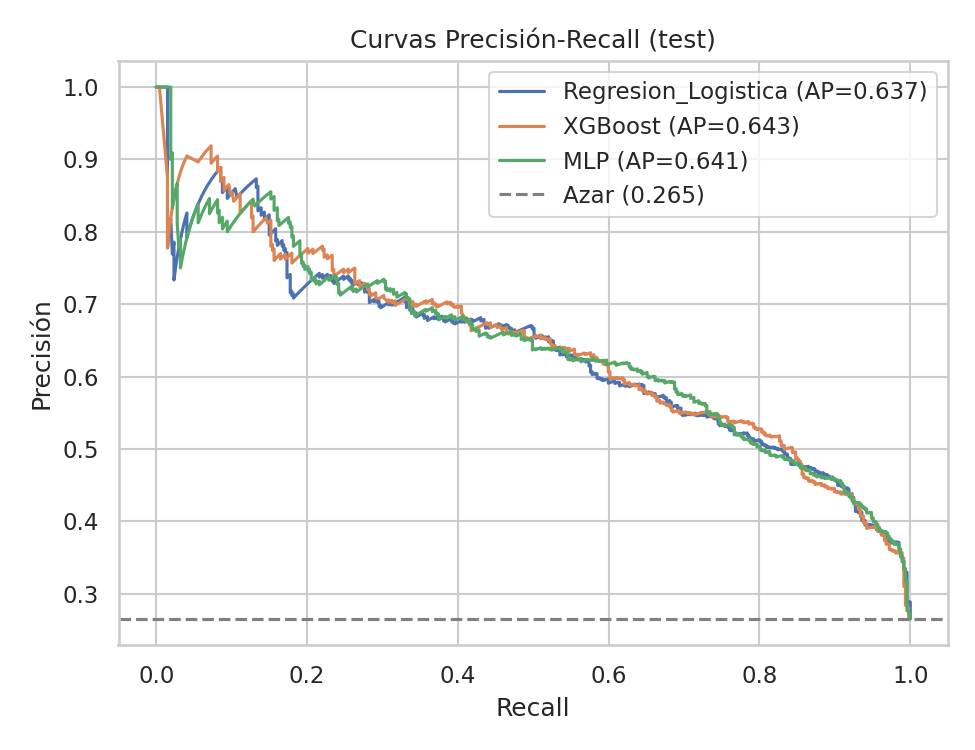

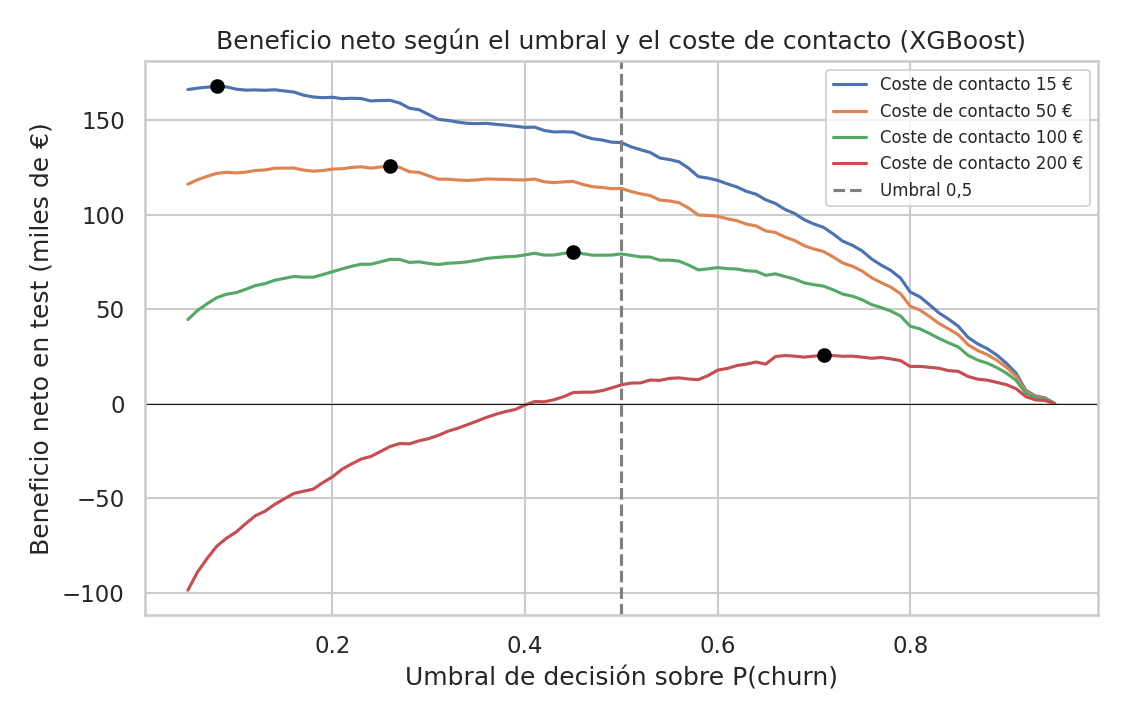

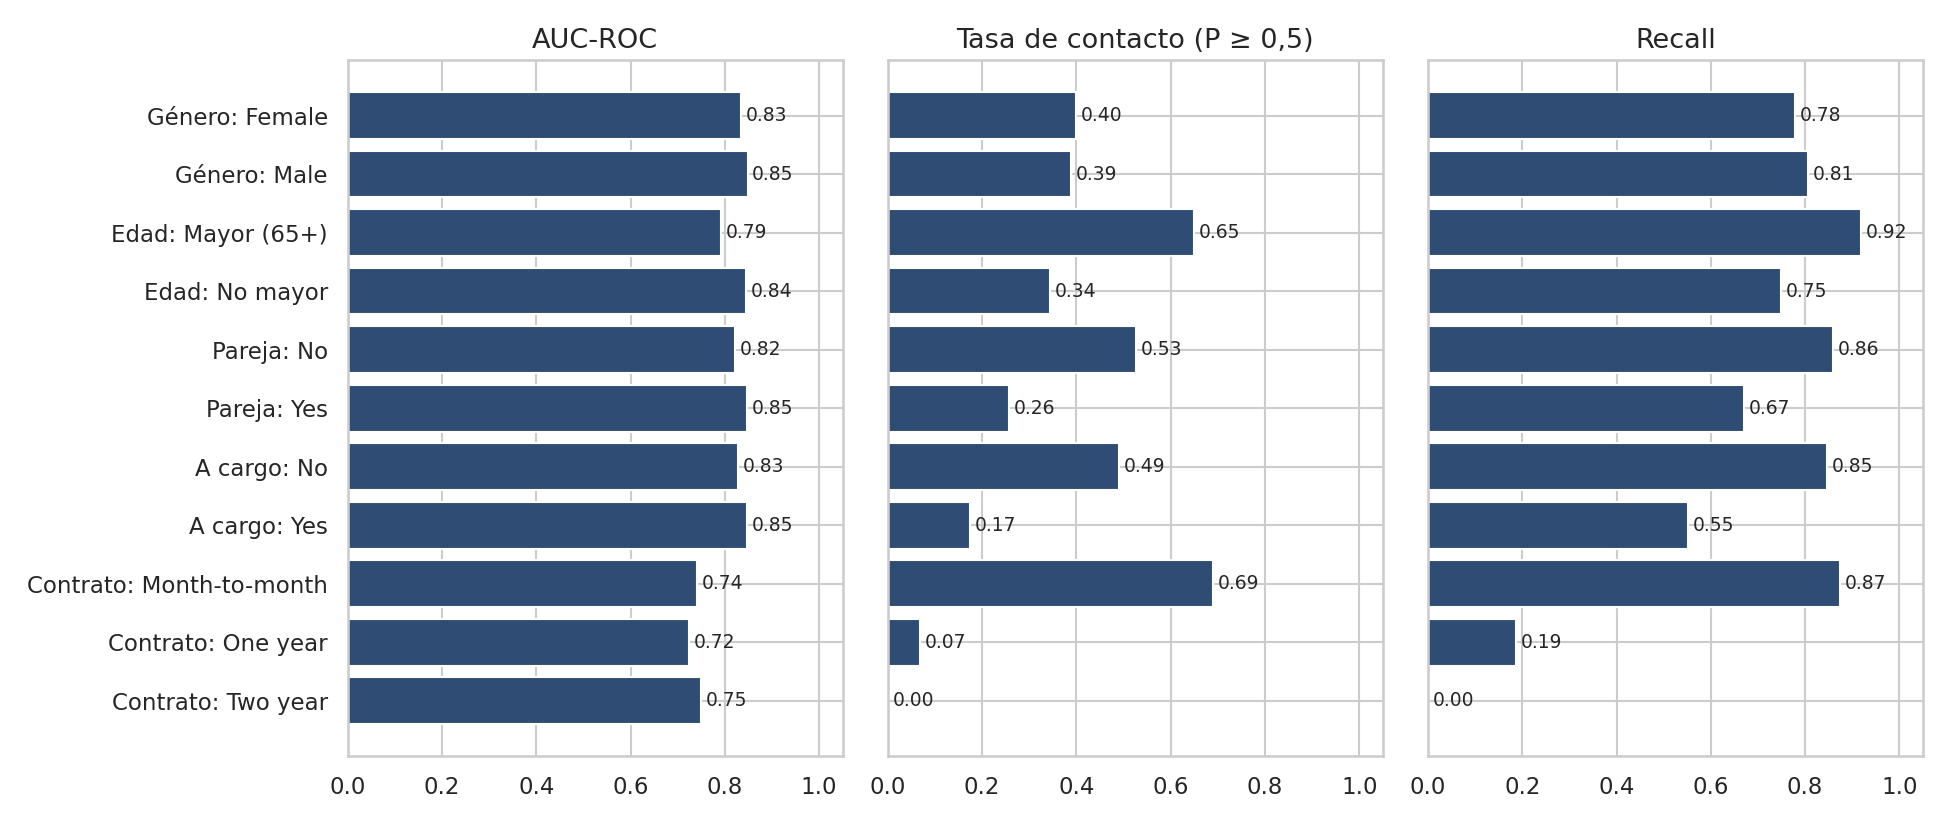

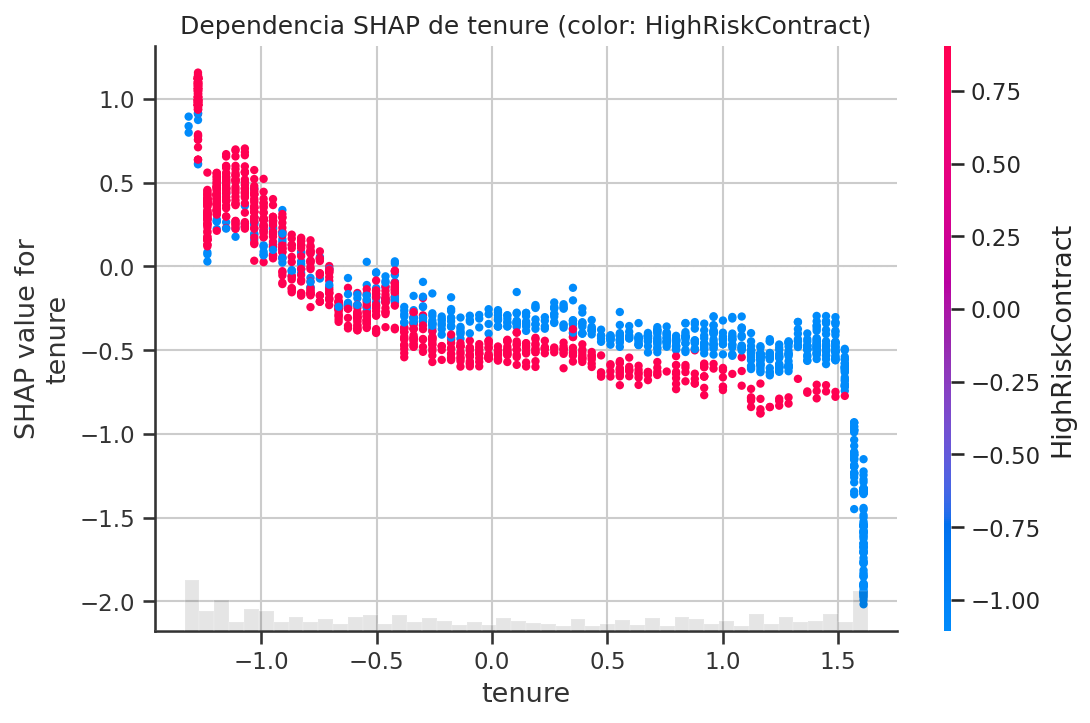

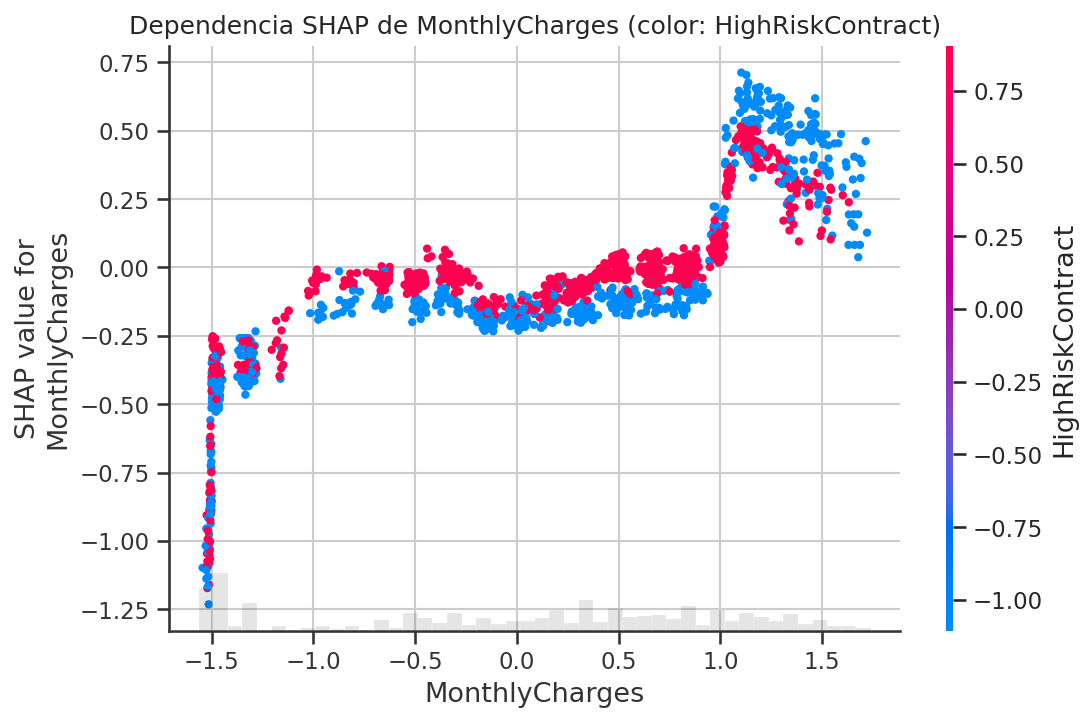

In [22]:
res8 = json.load(open(os.path.join(REPORTS_DIR, "diagnosticos_resultados.json")))
print("Average precision (test):", res8["average_precision"], "| prevalencia:", round(res8["prevalencia_test"], 4))
print("Cambio de signo del efecto SHAP de tenure (meses):", res8["shap_tenure_cambio_signo_meses"])
display(pd.read_csv(os.path.join(REPORTS_DIR, "diagnosticos_subgrupos.csv")))
for f in ["fig15_eda_tenure_charges", "fig16_churn_tenure_servicios", "fig17_boxplot_cargos_contrato", "fig18_heatmap_internet_contrato",
          "fig19_heatmap_pago_papel", "fig26_pr_curves", "fig27_umbral_optimo", "fig28_subgrupos", "fig29_shap_dependence_tenure", "fig30_shap_dependence_charges"]:
    display(Image(os.path.join(FIG_DIR, f + ".png"), width=600))


## 8. Calibración, métricas train/validación/test y simulación económica en test

Ejecuta `src/09_calibracion_y_valor_esperado.py`, que (i) calcula AUC, precisión, recall, F1 y Brier en entrenamiento, validación cruzada y test,
(ii) comprueba la calibración de las probabilidades (SMOTE las sobrestima) y las recalibra con regresión isotónica y sigmoide,
(iii) estima el CLV de los clientes de test con un Cox ajustado **solo con el entrenamiento**, y (iv) simula el ahorro neto de la campaña de retención
**solo sobre el conjunto de test y con las etiquetas reales**, frente a un contacto aleatorio (esperanza exacta), con IC bootstrap y análisis de sensibilidad al coste.


In [23]:
m9 = importlib.import_module("09_calibracion_y_valor_esperado")
m9.main()
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)


             modelo               conjunto    auc  precision  recall     f1  brier
Regresión Logística                  Train 0.8446     0.5136  0.7939 0.6237 0.1652
Regresión Logística Validación (CV 5-fold) 0.8410     0.5130  0.7896 0.6219 0.1667
Regresión Logística                   Test 0.8413     0.5132  0.7923 0.6229 0.1669
            XGBoost                  Train 0.8651     0.5497  0.7974 0.6508 0.1476
            XGBoost Validación (CV 5-fold) 0.8434     0.5272  0.7660 0.6246 0.1570
            XGBoost                   Test 0.8415     0.5339  0.7923 0.6379 0.1578
                MLP                  Train 0.8488     0.5248  0.7996 0.6337 0.1633
                MLP Validación (CV 5-fold) 0.8363     0.5184  0.7725 0.6205 0.1676
                MLP                   Test 0.8436     0.5140  0.7837 0.6209 0.1652


             modelo              version  prob_media  brier    ece    auc
                MLP calibrado (isotonic)      0.2645 0.1377 0.0261 0.8433
                MLP  calibrado (sigmoid)      0.2651 0.1378 0.0270 0.8437
                MLP sin calibrar (SMOTE)      0.4106 0.1652 0.1454 0.8436
Regresión Logística calibrado (isotonic)      0.2658 0.1381 0.0265 0.8414
Regresión Logística  calibrado (sigmoid)      0.2657 0.1382 0.0114 0.8417
Regresión Logística sin calibrar (SMOTE)      0.4121 0.1669 0.1469 0.8413
            XGBoost calibrado (isotonic)      0.2635 0.1365 0.0138 0.8440
            XGBoost  calibrado (sigmoid)      0.2641 0.1376 0.0181 0.8426
            XGBoost sin calibrar (SMOTE)      0.3849 0.1578 0.1197 0.8415


presupuesto  contactados  aleatorio  Riesgo × CLV (modelo calibrado)  Solo riesgo (modelo calibrado)  Solo CLV  Riesgo × CLV (sin calibrar)  Oráculo (cota superior)
         5%           88     8127.0                          30211.0                         29322.0    6020.0                      28188.0                  51323.0
        10%          176    16254.0                          55326.0                         52447.0   18683.0                      49981.0                  92420.0
        20%          352    32509.0                          92247.0                         90847.0   34191.0                      92959.0                 159047.0
        30%          528    48763.0                         123480.0                        118379.0   62807.0                     121901.0                 181132.0
        50%          880    81272.0                         156533.0                        150149.0  115663.0                     157291.0                 175852.0
       100

         Contrato   media  mediana   desv    min     max     n
0           Todos  1294.9   1341.9  612.2  351.0  2725.0  7043
1  Month-to-month  1198.2   1279.0  455.5  351.0  2198.1  3875
2        One year  1434.7   1539.9  688.4  409.5  2586.7  1473
3        Two year  1394.6   1488.7  789.7  424.0  2725.0  1695


                modelo  lift_decil1  ganancia_10  ganancia_30
0  Regresión Logística         2.75         27.4         65.3
1              XGBoost         2.75         27.4         65.1
2                  MLP         2.73         27.2         67.0
{
 "n_train": 5282,
 "n_test": 1761,
 "prevalencia_train": 0.2654297614539947,
 "prevalencia_test": 0.26519023282226006,
 "economia_20pct": {
  "contactados": 352,
  "modelo": 92246.54113973065,
  "aleatorio": 32508.855469672744,
  "ic95_modelo": [
   83716.90456527816,
   101151.9804173141
  ],
  "ic95_aleatorio": [
   29373.164996542593,
   35720.56156043035
  ],
  "ic95_diferencia": [
   52484.44768336984,
   67032.75684015386
  ],
  "valor_total_en_riesgo": 189051.6320514026,
  "clientes_que_abandonan_test": 467,
  "churners_capturados_modelo": 216,
  "churners_esperados_aleatorio": 93.34696195343555
 },
 "economia_sensibilidad_coste": [
  {
   "coste": 5,
   "modelo": 95766.54113973065,
   "aleatorio": 36028.855469672744,
   "contactar_a

,modelo,conjunto,auc,precision,recall,f1,brier
0,Regresión Logística,Train,0.8446,0.5136,0.7939,0.6237,0.1652
1,Regresión Logística,Validación (CV 5-fold),0.8410,0.5130,0.7896,0.6219,0.1667
2,Regresión Logística,Test,0.8413,0.5132,0.7923,0.6229,0.1669
3,XGBoost,Train,0.8651,0.5497,0.7974,0.6508,0.1476
4,XGBoost,Validación (CV 5-fold),0.8434,0.5272,0.7660,0.6246,0.1570
5,XGBoost,Test,0.8415,0.5339,0.7923,0.6379,0.1578
6,MLP,Train,0.8488,0.5248,0.7996,0.6337,0.1633
7,MLP,Validación (CV 5-fold),0.8363,0.5184,0.7725,0.6205,0.1676
8,MLP,Test,0.8436,0.5140,0.7837,0.6209,0.1652


,modelo,version,prob_media,brier,ece,auc
0,MLP,calibrado (isotonic),0.2645,0.1377,0.0261,0.8433
1,MLP,calibrado (sigmoid),0.2651,0.1378,0.0270,0.8437
2,MLP,sin calibrar (SMOTE),0.4106,0.1652,0.1454,0.8436
3,Regresión Logística,calibrado (isotonic),0.2658,0.1381,0.0265,0.8414
4,Regresión Logística,calibrado (sigmoid),0.2657,0.1382,0.0114,0.8417
5,Regresión Logística,sin calibrar (SMOTE),0.4121,0.1669,0.1469,0.8413
6,XGBoost,calibrado (isotonic),0.2635,0.1365,0.0138,0.8440
7,XGBoost,calibrado (sigmoid),0.2641,0.1376,0.0181,0.8426
8,XGBoost,sin calibrar (SMOTE),0.3849,0.1578,0.1197,0.8415


,presupuesto,contactados,aleatorio,Riesgo × CLV (modelo calibrado),Solo riesgo (modelo calibrado),Solo CLV,Riesgo × CLV (sin calibrar),Oráculo (cota superior)
0,5%,88,8127.0,30211.0,29322.0,6020.0,28188.0,51323.0
1,10%,176,16254.0,55326.0,52447.0,18683.0,49981.0,92420.0
2,20%,352,32509.0,92247.0,90847.0,34191.0,92959.0,159047.0
3,30%,528,48763.0,123480.0,118379.0,62807.0,121901.0,181132.0
4,50%,880,81272.0,156533.0,150149.0,115663.0,157291.0,175852.0
5,100%,1761,162637.0,162637.0,162637.0,162637.0,162637.0,162637.0


,coste,modelo,aleatorio,contactar_a_todos
0,5,95767.0,36029.0,180247.0
1,15,92247.0,32509.0,162637.0
2,50,79927.0,20189.0,101002.0
3,100,62327.0,2589.0,12952.0


,segmento,clientes,abandono_real,clv_medio,ahorro_neto
0,Alto riesgo / alto valor,477,0.461,1688.823,100709.767
1,Alto riesgo / bajo valor,405,0.459,962.966,49409.087
2,Bajo riesgo / alto valor,404,0.089,1906.443,14938.438
3,Bajo riesgo / bajo valor,475,0.053,640.330,-2420.659


Presupuesto 20% (352 clientes): modelo 92,247 EUR vs aleatorio 32,509 EUR


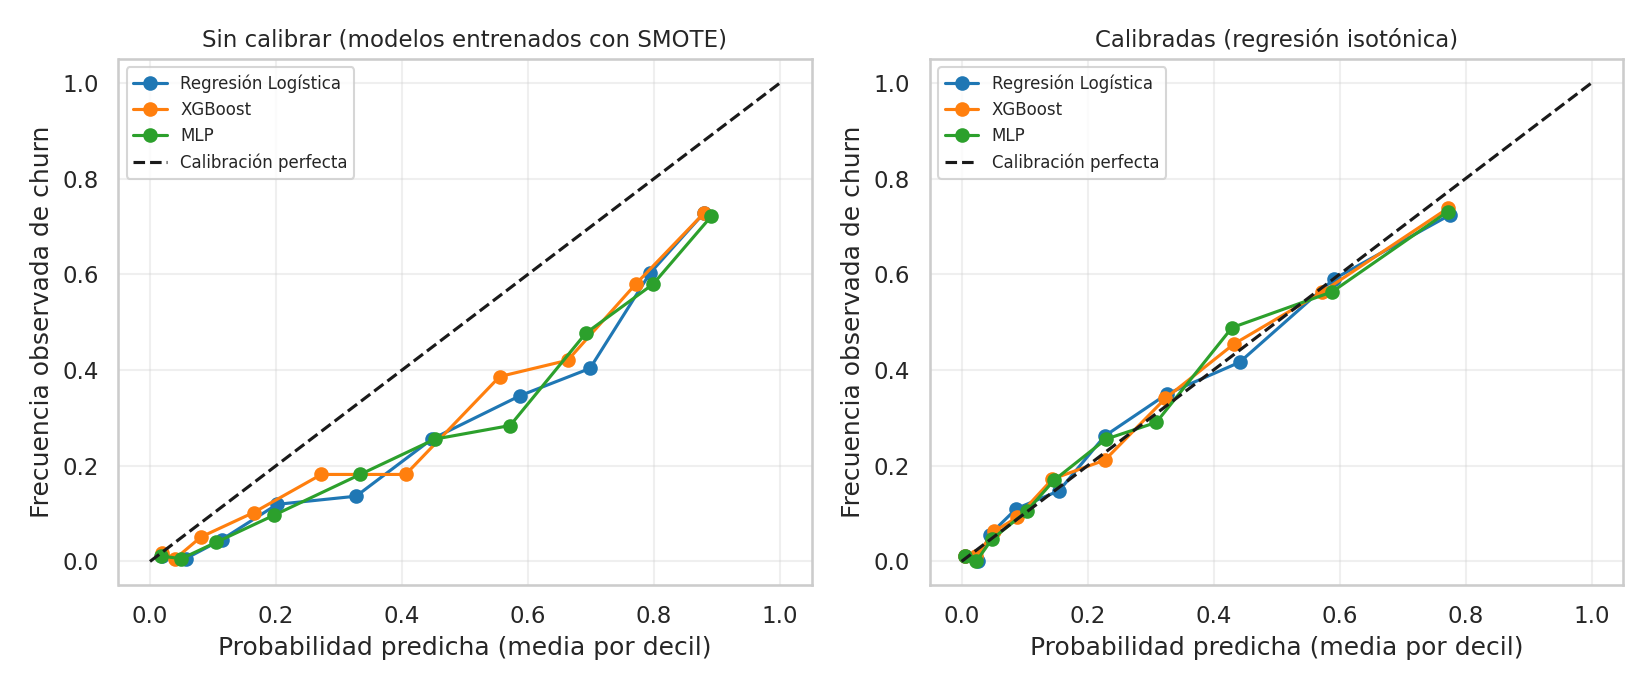

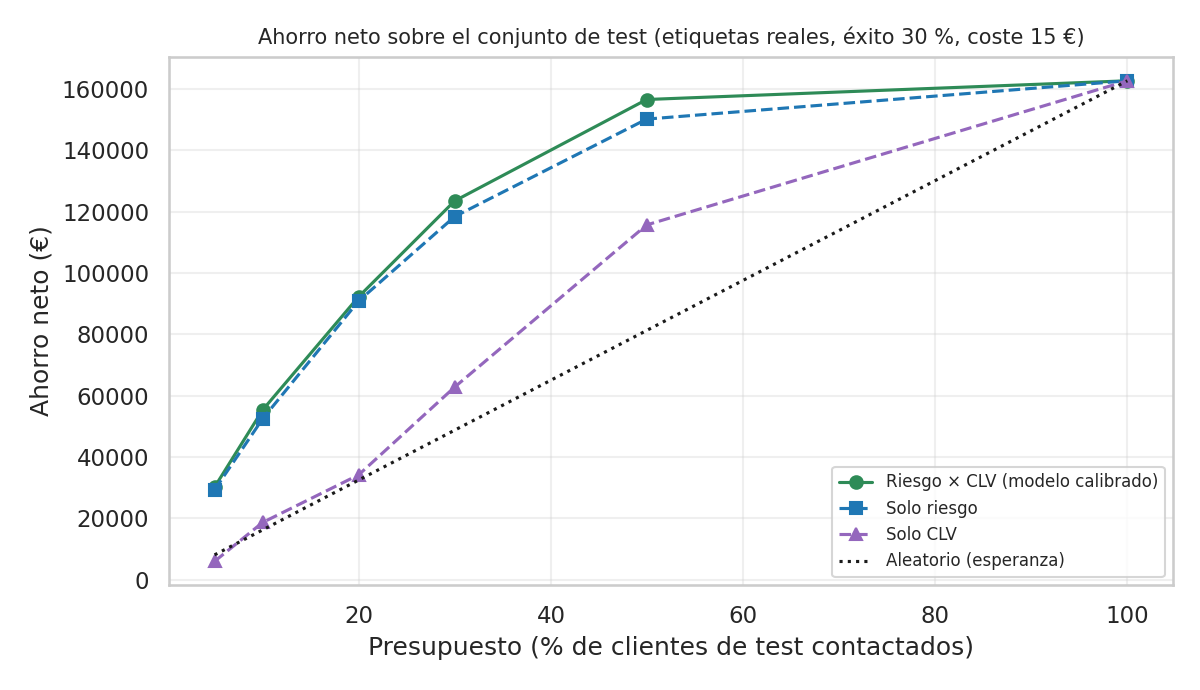

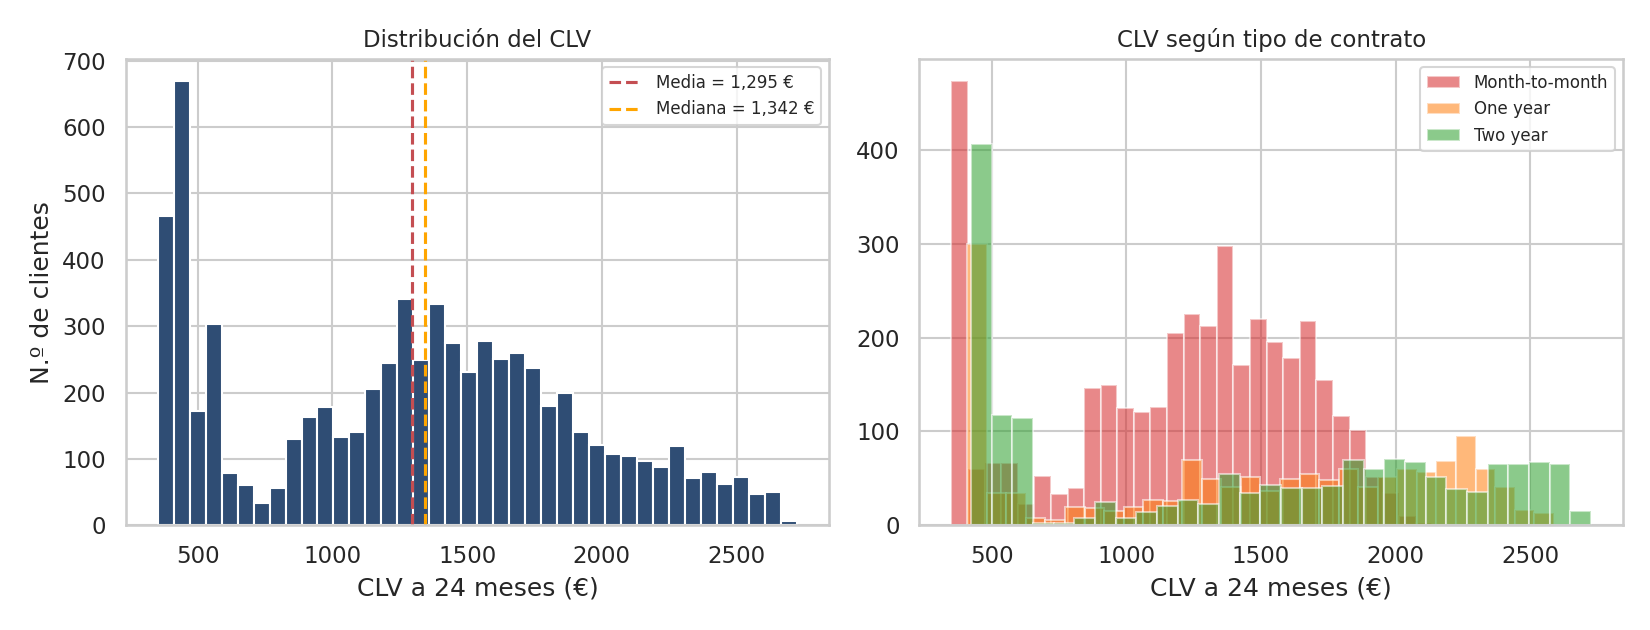

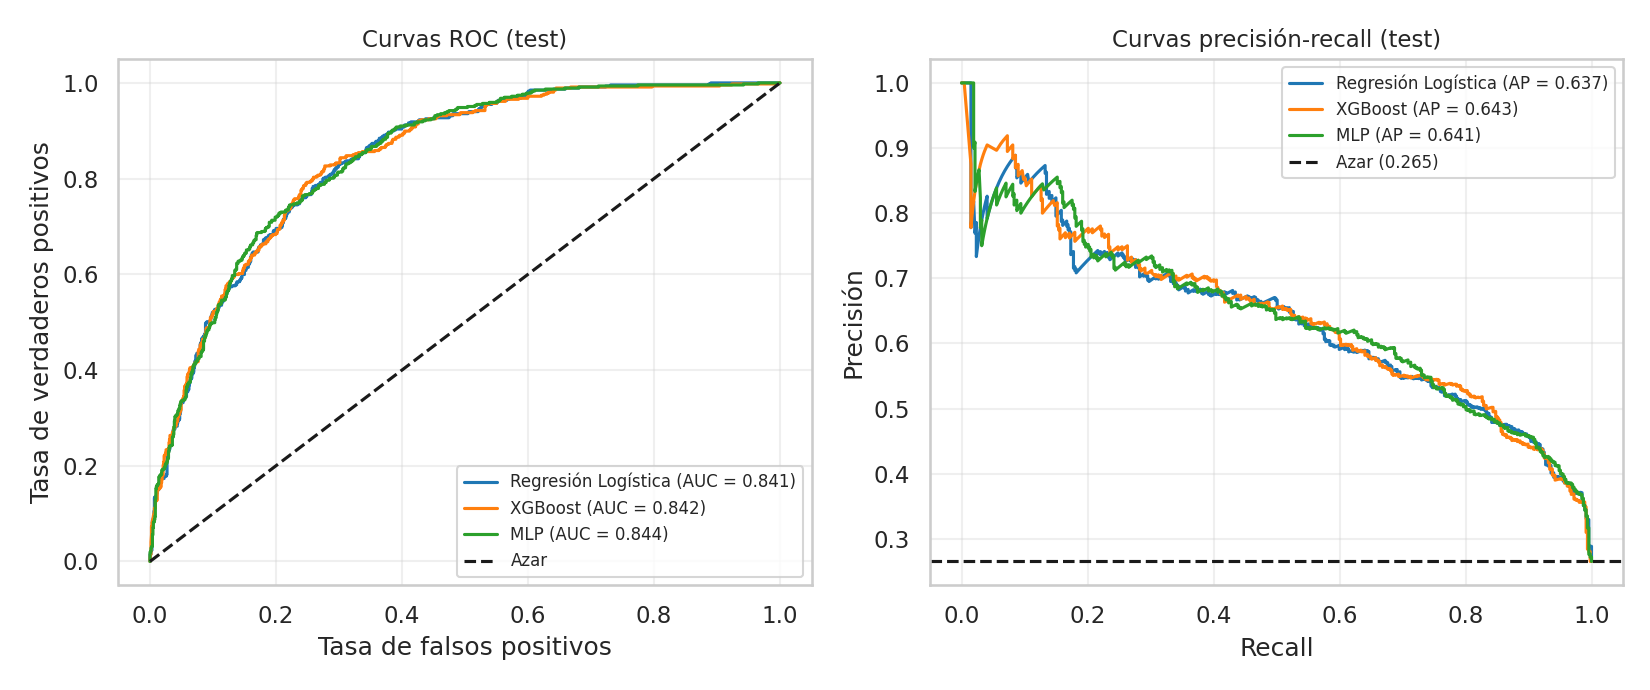

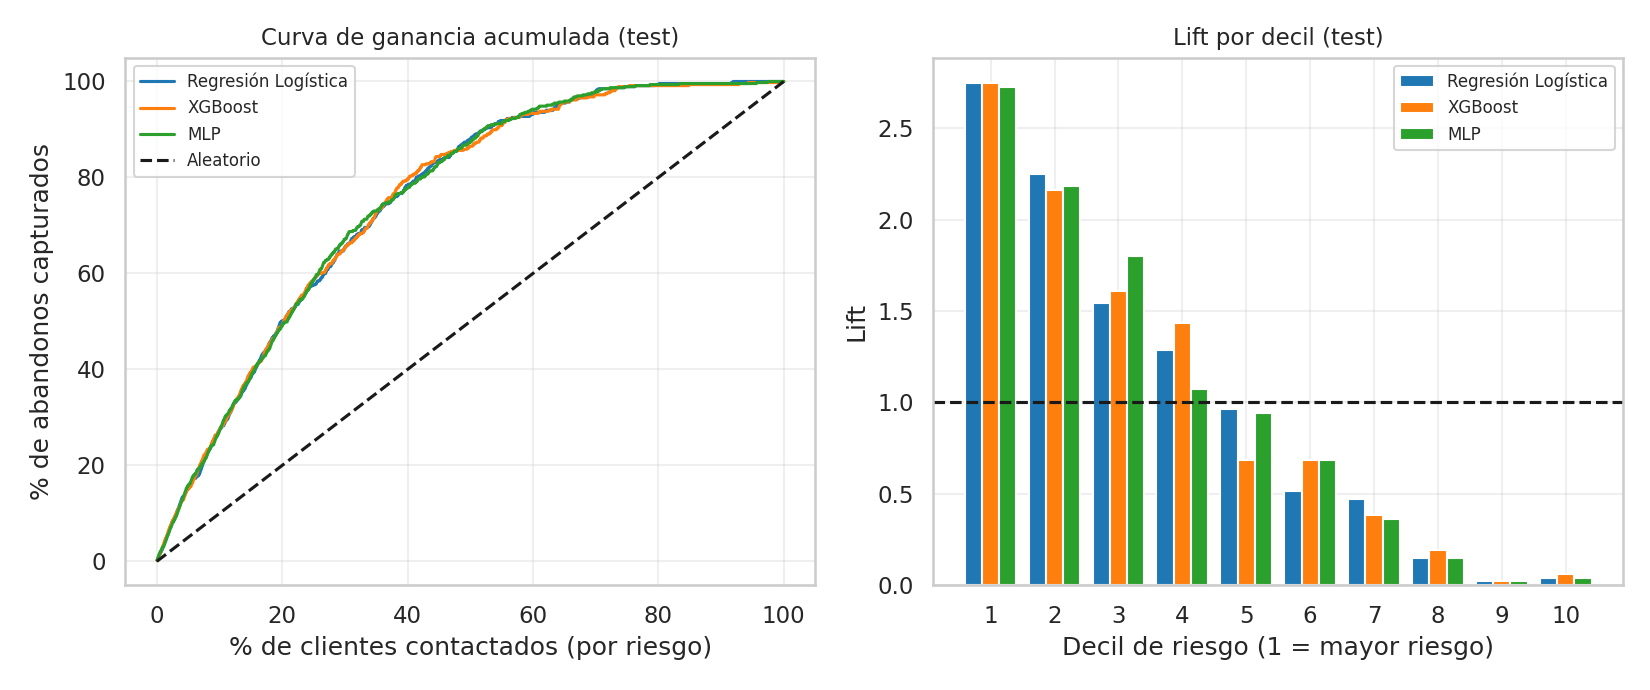

In [24]:
res9 = json.load(open(os.path.join(REPORTS_DIR, "calibracion_valor_esperado.json")))
display(pd.read_csv(os.path.join(REPORTS_DIR, "metricas_train_val_test.csv")))
display(pd.read_csv(os.path.join(REPORTS_DIR, "calibracion_probabilidades.csv")))
display(pd.read_csv(os.path.join(REPORTS_DIR, "economia_test_por_presupuesto.csv")))
display(pd.read_csv(os.path.join(REPORTS_DIR, "economia_test_sensibilidad_coste.csv")))
display(pd.read_csv(os.path.join(REPORTS_DIR, "segmentos_riesgo_valor.csv")))
e20 = res9["economia_20pct"]
print(f"Presupuesto 20% ({e20['contactados']} clientes): modelo {e20['modelo']:,.0f} EUR vs aleatorio {e20['aleatorio']:,.0f} EUR")
for f in ["fig31_calibracion_antes_despues", "fig32_ahorro_test_presupuesto", "fig33_distribucion_clv", "fig34_roc_pr_conjuntas", "fig35_ganancia_lift_conjuntas"]:
    display(Image(os.path.join(FIG_DIR, f + ".png"), width=650))


## Líneas futuras

- Modelos de supervivencia que relajen el supuesto de riesgos proporcionales (tiempo discreto, DeepHit) y búsqueda de hiperparámetros más amplia para DeepSurv.
- CLV condicionado a la antigüedad actual, calculado sobre margen y con tasa de descuento.
- Un **Causal Forest** (`econml`) o un modelo de uplift sobre un experimento A/B real o simulado para estimar la tasa de éxito de retención.
